
# Route Intelligence
## Predicción de tiempos de viaje para la jornada siguiente y generación de matrices origen-destino

**Proyecto Integrador · Equipo 42 · Maestría en Inteligencia Artificial Aplicada · noviembre de 2026**

**Integrantes:**
- Luis Ángel Herrera Flores
- Francisco Natanael Ortiz Martínez
- Edgar Iván Rosas Gómez

**Objetivo.** Desarrollar y evaluar modelos para estimar los tiempos de desplazamiento por arista durante la jornada siguiente, utilizando únicamente información disponible hasta las 17:55 del día anterior. Comparar una referencia histórica, un modelo residual lineal, una red neuronal sin propagación espacial y dos variantes de redes neuronales sobre grafos (GNN). Analizar los perfiles horarios de las predicciones y evaluar la precisión de las matrices origen-destino (OD) obtenidas a partir de los tiempos estimados.

**Escenario experimental.** Se consideran predicciones para los intervalos de cinco minutos comprendidos entre las 08:00 y las 15:55 de cada jornada. Los modelos utilizan información histórica de tráfico, características de calendario y atributos de una red dirigida construida a partir de PEMS-BAY (2017). El experimento incluye evaluación temporal, visualización de resultados y generación de matrices OD en archivos CSV.

**Relación con los avances anteriores.** Este trabajo complementa la reconstrucción contemporánea de tiempos de desplazamiento desarrollada en los Avances 4 y 5 mediante regresión Ridge y 32 consultas OD guía simuladas. Ambos enfoques utilizan la misma red experimental, pero responden a problemas distintos: uno anticipa condiciones futuras a partir de información histórica y el otro reconstruye el estado de la red utilizando observaciones del instante de interés.

**Alcance y limitaciones.** Las predicciones y matrices OD corresponden a una red experimental derivada de PEMS-BAY, no a un sistema de tráfico en operación. Se prepara una salida de datos para explorar su posible integración con el modelo de optimización de Berth y Trigos, pero todavía no se ha acordado la interfaz definitiva ni se ha ejecutado o validado dicho optimizador. El experimento tampoco incorpora predicción de incidentes mediante fuentes textuales o modelos de lenguaje.



## 1. Pregunta de investigación y punto de integración

Berth (2025) y Berth y Trigos (2025) desarrollan modelos de ruteo de vehículos con ventanas de tiempo que requieren información sobre los tiempos de desplazamiento entre nodos logísticos. Durante la ejecución de las rutas, las modificaciones de estos tiempos permiten evaluar la factibilidad de la planeación original y, cuando corresponde, activar mecanismos de recuperación. En sus experimentos, Berth introduce perturbaciones exógenas de los tiempos de viaje, pero no desarrolla un procedimiento para estimarlas a partir de observaciones de tráfico. Esto identifica una oportunidad de integración: proporcionar estimaciones de tiempos de desplazamiento que puedan utilizarse en los procesos de planeación y recuperación de rutas.

En el desarrollo del Proyecto Integrador se han abordado dos problemas relacionados, pero distintos: **la actualización de los tiempos de viaje durante la ejecución** y **la predicción anticipada para el siguiente turno**. El primero se estudió en los Avances 4 y 5 mediante la reconstrucción del estado de la red a partir de 32 consultas origen-destino (OD) guía simuladas, utilizando regresión Ridge y combinaciones de modelos. El presente experimento aborda el segundo problema y retoma la propuesta del Dr. Camacho de explorar redes neuronales sobre grafos (GNN) para aprovechar las relaciones espaciales entre segmentos viales.

Sea $G=(V,E)$ el grafo dirigido construido a partir de PEMS-BAY, donde $V$ representa el conjunto de nodos y $E$ el conjunto de aristas. La red experimental contiene 322 nodos, incluidos 13 macronodos de intercambio, y 345 aristas dirigidas. Para cada arista $e\in E$, se denota por $\tau_e(t)$ su tiempo de desplazamiento en el instante $t$, expresado en minutos. El problema consiste en estimar este tiempo para un instante futuro $t^*$ utilizando únicamente información disponible hasta un instante anterior $t_0<t^*$.

Sea $\mathcal{I}_{t_0}$ el conjunto de información disponible al momento de realizar la predicción. En este experimento comprende las observaciones históricas de tráfico permitidas por el corte temporal, las características de calendario y los atributos de la red utilizados por los modelos. No incluye observaciones posteriores a $t_0$, consultas OD del instante objetivo ni información semántica sobre incidentes. La predicción se expresa como:

$$
\widehat{\tau}_e(t^*\mid\mathcal{I}_{t_0}), \qquad e\in E,
$$

donde $\widehat{\tau}_e$ representa el tiempo positivo de desplazamiento estimado para la arista $e$.

Los tiempos predichos se utilizan como pesos del grafo dirigido para calcular, mediante Dijkstra, matrices de tiempos OD entre los nodos seleccionados. Se evalúa tanto la precisión de las predicciones por arista como la de los tiempos de recorrido resultantes, con el fin de determinar cómo los errores de estimación afectan las matrices OD. Estas matrices representan un posible insumo para el modelo de Berth y Trigos, aunque su integración y sus efectos sobre las decisiones de ruteo todavía no se han evaluado.

El escenario experimental contempla una jornada de ocho horas, de 08:00 a 15:55, con predicciones cada cinco minutos e información de tráfico disponible hasta las 17:55 del día anterior. Para cada instante objetivo, Dijkstra calcula los caminos mínimos suponiendo que los tiempos de las aristas permanecen constantes durante el recorrido. La duración de la jornada y la generación de 96 matrices OD son decisiones experimentales, no requisitos de la formulación de Berth y Trigos. El experimento evalúa la capacidad predictiva de los modelos y la contribución de las relaciones espaciales, sin modificar ni ejecutar el procedimiento de optimización y recuperación de rutas.



## 2. Fuentes, integridad y alcance de los datos

Se reutilizan los archivos originales de `routing_dataset_v1` sin modificar su contenido: `nodes.csv`, `edges.csv`, `edge_travel_times.parquet` y `manifest.json`. La red experimental, construida previamente a partir de PEMS-BAY, contiene 322 nodos (309 asociados con sensores y 13 macronodos de intercambio) y 345 aristas dirigidas, de las cuales 273 corresponden a corredores y 72 a conexiones funcionales de intercambio. La plausibilidad de estas últimas se examinó con apoyo de OpenStreetMap (OSM), sin que ello constituya una validación de todas las conexiones y restricciones de circulación de la red real.

Los tiempos de desplazamiento por arista se derivaron de las velocidades registradas por los sensores y de las longitudes estimadas de los segmentos, con una resolución temporal de cinco minutos. Por tanto, no constituyen mediciones independientes de los tiempos reales de recorrido, particularmente en las conexiones asociadas con macronodos.

La topología de la red vial original se conserva para el cálculo de las matrices OD en todos los experimentos.


In [1]:
# En Google Colab, se monta Drive solo si el dataset no está disponible junto a la libreta.
from pathlib import Path
if Path('routing_dataset_v1/edges.csv').is_file() or Path('../routing_dataset_v1/edges.csv').is_file():
    print('Datos locales detectados; no es necesario montar Google Drive.')
else:
    try:
        from google.colab import drive
    except ImportError:
        print('Entorno local: se buscará routing_dataset_v1 en las rutas configuradas.')
    else:
        drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt
from IPython.display import display

# Se admite la ruta habitual de Google Drive del proyecto.
CANDIDATOS = [
    Path('routing_dataset_v1'),
    Path('../routing_dataset_v1'),
    Path('/content/drive/MyDrive/Route Intelligence/routing_dataset_v1'),
]
DATA_DIR = next((p for p in CANDIDATOS
                 if (p/'edges.csv').is_file() and (p/'edge_travel_times.parquet').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        'No se encontró routing_dataset_v1. Extrae el paquete junto a la libreta '
        'o monta Drive y usa MyDrive/Route Intelligence/routing_dataset_v1.'
    )
print('Datos fuente:', DATA_DIR.resolve())

edges = pd.read_csv(DATA_DIR/'edges.csv')
nodes = pd.read_csv(DATA_DIR/'nodes.csv')
manifest = json.loads((DATA_DIR/'manifest.json').read_text(encoding='utf-8'))
edge_ids = edges['edge_id'].astype(str).tolist()
try:
    df = pd.read_parquet(DATA_DIR/'edge_travel_times.parquet')
except ImportError:
    # Alternativa de lectura para el archivo particular de este proyecto.
    # Está incluida en routing_dataset_v1/ para entornos sin pyarrow.
    import sys
    sys.path.insert(0, str(DATA_DIR.resolve()))
    from parquet_light_reader import get_columns
    columnas = get_columns(str(DATA_DIR/'edge_travel_times.parquet'), edge_ids+['timestamp'])
    timestamps = pd.to_datetime(columnas.pop('timestamp'),unit='ns')
    df = pd.DataFrame(columnas,index=timestamps)
if 'timestamp' in df.columns:
    t = df.pop('timestamp')
    df.index = pd.to_datetime(t,unit='ns' if pd.api.types.is_integer_dtype(t) else None)
Y = df.reindex(columns=edge_ids).sort_index().astype('float32')
assert Y.shape == (52116,345), f'Dimensiones inesperadas: {Y.shape}'
assert edges.edge_id.is_unique and not edges[['from','to']].isna().any().any()
assert np.isfinite(Y.to_numpy()).all() and (Y.to_numpy() > 0).all()
assert len(nodes)==322 and (edges.edge_type=='corridor').sum()==273
assert (nodes.node_type=='interchange').sum()==13
assert Y.index.is_unique and Y.index.is_monotonic_increasing
print(f'{len(nodes)} nodos, {len(edges)} aristas, {len(Y):,} instantes de cinco minutos')
print('Cobertura:', Y.index.min(), 'a',Y.index.max())
print('Unidad de tiempo: minutos; 13 macronodos funcionales')

Datos fuente: /content/drive/MyDrive/Route Intelligence/routing_dataset_v1
322 nodos, 345 aristas, 52,116 instantes de cinco minutos
Cobertura: 2017-01-01 00:00:00 a 2017-06-30 23:55:00
Unidad de tiempo: minutos; 13 macronodos funcionales


## 3. Relaciones espaciales entre aristas

Para incorporar las relaciones espaciales al modelo predictivo, se construye un grafo auxiliar de paso de mensajes en el que cada arista dirigida de la red vial se representa como un nodo. Esta representación incluye tanto las aristas de corredor como las conexiones funcionales asociadas con los macronodos de intercambio.

Se establece una relación dirigida entre dos aristas $e_i=(u,v)$ y $e_j=(v,w)$ cuando el nodo de destino de la primera coincide con el nodo de origen de la segunda. A partir de esta regla se construyen matrices de vecindad que permiten a la GNN agregar información de aristas predecesoras y sucesoras durante el aprendizaje.

Los macronodos representan conexiones funcionales entre corredores y permiten incorporar posibles dependencias espaciales entre segmentos de distintas vías. Sin embargo, dado que estas conexiones son aproximaciones de los intercambios reales, no es evidente que la propagación de información a través de ellas mejore las predicciones. Para examinar su contribución, se compara la GNN completa con una variante de ablación que desactiva únicamente los mensajes que atraviesan macronodos, manteniendo la misma arquitectura neuronal.

La vecindad definida representa la consecutividad entre aristas según la estructura del grafo experimental, sin verificar todas las restricciones físicas de giro o circulación de la red real. La ablación modifica únicamente las relaciones de paso de mensajes; la topología de la red vial utilizada posteriormente por Dijkstra permanece intacta.



In [3]:
source = edges['from'].astype(str).to_numpy()
target = edges['to'].astype(str).to_numpy()
node_type = nodes.set_index('node_id')['node_type'].to_dict()
macro_nodes = {str(k) for k,v in node_type.items() if v=='interchange'}
macro_nodes |= set(edges.loc[edges.edge_type!='corridor','node_id'].dropna().astype(str))
# aristas en las filas (e_j) que reciben señales de otras aristas e_i
transition = (source[:,None]==target[None,:]).astype('float32')
np.fill_diagonal(transition,0.0)
macro_at_start = np.array([x in macro_nodes for x in source])
transition_nomacro = transition.copy()
transition_nomacro[macro_at_start,:]=0.0

def row_norm(A):
    d=A.sum(axis=1,keepdims=True)
    return sparse.csr_matrix(np.divide(A,d,out=np.zeros_like(A),where=d!=0))
A_up_full = row_norm(transition)
A_down_full = row_norm(transition.T)
A_up_nomacro = row_norm(transition_nomacro)
A_down_nomacro = row_norm(transition_nomacro.T)
print('Macronodos:',len(macro_nodes),'| aristas:',len(edges), '| corredor:',int((edges.edge_type=='corridor').sum()))
print('Relaciones dirigidas (e_i → e_j): total',int(transition.sum()),
      '| a través de macronodos',int((transition-transition_nomacro).sum()),
      '| restantes',int(transition_nomacro.sum()))


# Verificaciones de integridad del grafo y alineación de datos
assert len(macro_nodes) == 13, "Cantidad inesperada de macronodos."

assert int(transition.sum()) == 419, (
    "Cantidad inesperada de relaciones espaciales."
)

assert int((transition - transition_nomacro).sum()) == 110, (
    "La ablación no desactivó las 110 relaciones esperadas."
)

assert list(map(str, edge_ids)) == list(map(str, Y.columns)), (
    "El orden de las aristas no coincide con las columnas de Y."
)

Macronodos: 13 | aristas: 345 | corredor: 273
Relaciones dirigidas (e_i → e_j): total 419 | a través de macronodos 110 | restantes 309


### Interpretación de las relaciones espaciales

Se identifican 419 relaciones dirigidas de paso de mensajes entre las 345 aristas de la red vial. De ellas, 110 corresponden a transiciones cuyo nodo compartido es uno de los 13 macronodos de intercambio.

La configuración de ablación desactiva estas 110 relaciones y conserva las 309 restantes. Ambas configuraciones utilizan la misma topología vial para calcular las matrices OD, aunque pueden producir diferentes estimaciones de los tiempos de desplazamiento.

La comparación posterior permitirá examinar si habilitar el intercambio de información a través de los macronodos mejora la precisión predictiva de la GNN bajo las condiciones del experimento.




## 4. Variables objetivo y protocolo temporal

### Escenario de predicción

El experimento considera la predicción de tiempos de desplazamiento para la jornada siguiente, entre las 08:00 y las 15:55, con intervalos de cinco minutos. El momento de emisión se fija a las 18:00 del día anterior, utilizando observaciones de tráfico disponibles hasta las 17:55. Por tanto, se generan predicciones para 96 instantes objetivo a partir de un mismo corte de información.

Cada instante se estima directamente, sin utilizar las predicciones de intervalos anteriores como entradas para los siguientes. Este procedimiento evita la acumulación recursiva de errores, aunque no modela explícitamente la evolución secuencial del tráfico durante la jornada.

### Referencia histórica y formulación residual

Para representar los patrones habituales de tráfico, se construye una referencia histórica para cada arista utilizando las observaciones de enero a marzo de 2017. Esta referencia corresponde a la mediana de los tiempos registrados para cada combinación de día de la semana e intervalo de cinco minutos. Por ejemplo, la referencia de una arista para un lunes a las 08:00 se obtiene a partir de sus observaciones correspondientes a los lunes a las 08:00 de ese periodo.

La referencia se mantiene fija durante las evaluaciones posteriores. Su valor para un instante futuro depende del día de la semana y la hora que se desea predecir, pero no incorpora observaciones de ese instante ni se actualiza con registros posteriores al periodo de ajuste.

Sea $m_e(t)$ la referencia histórica de la arista $e$ para el instante $t$, y $\tau_e(t)$ su tiempo de desplazamiento. El modelo M0 utiliza directamente la referencia histórica como estimación, mientras que los modelos de aprendizaje predicen desviaciones respecto de ella mediante el residuo logarítmico:

$$
r_e(t)=\log\left(\frac{\tau_e(t)}{m_e(t)}\right)
$$

Esta transformación expresa las desviaciones en términos relativos, lo que facilita trabajar con aristas cuyos tiempos habituales son diferentes. Un residuo nulo indica que el tiempo coincide con la referencia histórica; los valores positivos representan tiempos mayores y los negativos, menores. La variación relativa equivalente se obtiene mediante $\exp(r_e(t))-1$.

A partir del residuo predicho, el tiempo de desplazamiento se recupera como:

$$
\widehat{\tau}_e(t)=m_e(t)\exp\left(\widehat{r}_e(t)\right)
$$

De esta manera, los modelos aprenden correcciones respecto del comportamiento habitual, en lugar de estimar directamente los tiempos absolutos. La transformación también garantiza predicciones positivas, siempre que las referencias históricas sean positivas.

### Características de entrada

Para cada arista e instante objetivo se construye un vector de diez características utilizado por los modelos de aprendizaje:

| Grupo | Características | Construcción y justificación |
|---|---|---|
| Constante (1) | Término constante | Valor fijo de 1, incorporado al vector de entrada. |
| Tráfico histórico (3) | Día anterior, semana anterior y último registro disponible | Residuos logarítmicos de los tiempos observados en el mismo intervalo del día anterior, siete días antes y a las 17:55 del día previo. Se incluyen para aprovechar información reciente y posibles patrones de persistencia diaria y semanal. |
| Atributos de arista (2) | Longitud y tipo | La longitud en kilómetros se transforma mediante $\log(1+d_e)$, donde $d_e$ es la longitud de la arista. El tipo se codifica como 0 para corredores y 1 para conexiones de intercambio. |
| Calendario (4) | Seno y coseno del intervalo horario y del día de la semana | Codificación cíclica de los 288 intervalos diarios y los siete días de la semana, que permite representar patrones temporales respetando su periodicidad. |

Los indicadores de tráfico histórico se calculan respecto de la mediana correspondiente al momento de cada observación, no al instante futuro que se desea predecir. Las tres referencias temporales permiten incorporar información sobre condiciones recientes y posibles patrones recurrentes, sin presuponer que su contribución individual a la precisión haya sido demostrada.

Los modelos de aprendizaje utilizan las mismas diez características. Las variantes GNN incorporan, además, las relaciones espaciales del grafo auxiliar descrito en la sección 3. No se incluyen otros atributos físicos, como el número de carriles, ni información contextual sobre incidentes.

### Entrenamiento, restricciones y evaluación temporal

Las referencias históricas se calculan con observaciones del 1 de enero al 31 de marzo de 2017. Los modelos se entrenan con jornadas del 9 de enero al 31 de marzo y se validan del 2 al 30 de abril. La validación se utiliza, entre otras cosas, para seleccionar la época de entrenamiento de las redes neuronales. Mayo y junio se emplean como periodos de diagnóstico, pero no constituyen pruebas completamente inéditas, pues ya fueron examinados durante el desarrollo previo del proyecto.

La implementación incluye restricciones heurísticas sobre los residuos logarítmicos. Las tres características históricas se acotan al intervalo $[-2.5,2.5]$, mientras que los residuos objetivo utilizados para entrenar las redes neuronales se restringen a $[-3,3]$. Adicionalmente, las predicciones residuales se acotan a $[-2.5,2.5]$ en los modelos neuronales y a $[-4,4]$ en el modelo lineal, antes de recuperar los tiempos de desplazamiento.

Estos límites se introdujeron para moderar la influencia de valores extremos y restringir la magnitud de las salidas, pero sus valores no fueron seleccionados mediante un análisis de sensibilidad ni se ha demostrado que mejoren la precisión. Además, pueden reducir la información disponible sobre condiciones de tráfico inusuales o limitar las desviaciones que los modelos son capaces de representar. Su aplicación y sus posibles efectos deben considerarse al interpretar los resultados.

Dado que las referencias históricas se ajustan utilizando todo enero-marzo, los ejemplos del propio periodo de entrenamiento no reproducen estrictamente la información que habría estado disponible en cada fecha. Para las jornadas de abril en adelante, en cambio, las referencias están previamente ajustadas y las características de entrada se construyen exclusivamente con observaciones anteriores al corte correspondiente.


In [4]:
ix = Y.index
values = Y.to_numpy(dtype=np.float32)
stamp_to_pos = pd.Series(np.arange(len(ix)), index=ix)
slot = ix.hour*12+ix.minute//5
fit_mask = (ix >= pd.Timestamp('2017-01-01')) & (ix < pd.Timestamp('2017-04-01'))
reference = Y.loc[fit_mask]
grp_ref = reference.groupby([reference.index.dayofweek,reference.index.hour*12+reference.index.minute//5]).median()
grp_ref.index.names=['weekday','slot_5min']
slot_ref = reference.groupby(reference.index.hour*12+reference.index.minute//5).median()
all_ref = reference.median(axis=0).to_numpy(dtype='float32')

def historical_median(times):
    keys = pd.MultiIndex.from_arrays([times.dayofweek,times.hour*12+times.minute//5],names=['weekday','slot_5min'])
    out = grp_ref.reindex(keys).to_numpy(dtype='float32')
    fallback = slot_ref.reindex(times.hour*12+times.minute//5).to_numpy(dtype='float32')
    out = np.where(np.isfinite(out),out,fallback)
    out = np.where(np.isfinite(out),out,all_ref)
    assert np.isfinite(out).all() and (out>0).all()
    return out

# Semanas completas como observaciones de historial.
static_len = np.broadcast_to(np.log1p(edges['distance_km'].to_numpy(dtype='float32')),(96,len(edges)))
static_macro = np.broadcast_to((edges.edge_type!='corridor').to_numpy(dtype='float32'),(96,len(edges)))

def inputs_disponibles_al_corte(day):
    """Construye entradas para pronosticar una jornada SIN consultar su tráfico futuro."""
    day=pd.Timestamp(day).normalize()
    targets = pd.date_range(day+pd.Timedelta(hours=8), periods=96, freq='5min')
    yesterday = targets-pd.Timedelta(days=1)
    last_week = targets-pd.Timedelta(days=7)
    cut = day-pd.Timedelta(days=1)+pd.Timedelta(hours=17,minutes=55)
    issue_at=cut+pd.Timedelta(minutes=5)
    if min(last_week)<ix[0]: return None
    assert yesterday.max()<=cut and last_week.max()<=cut
    # Solo se buscan observaciones hasta el corte, no los targets del día pronosticado.
    lookups=[yesterday,last_week,pd.DatetimeIndex([cut])]
    if any(not z.isin(ix).all() for z in lookups): return None
    b=historical_median(targets)
    yp=Y.loc[yesterday].to_numpy(dtype='float32')
    wp=Y.loc[last_week].to_numpy(dtype='float32')
    cutp=np.broadcast_to(Y.loc[cut].to_numpy(dtype='float32'),b.shape)
    r_yest=np.clip(np.log(yp/historical_median(yesterday)),-2.5,2.5)
    r_week=np.clip(np.log(wp/historical_median(last_week)),-2.5,2.5)
    r_cut=np.clip(np.log(cutp/historical_median(pd.DatetimeIndex([cut]))),-2.5,2.5)
    slotnum=np.asarray(targets.hour*12+targets.minute//5)
    daynum=targets.dayofweek.to_numpy()
    feats = [
        np.ones_like(b),
        r_yest, r_week, r_cut,
        static_len,static_macro,
        np.broadcast_to(np.sin(2*np.pi*slotnum/288)[:,None],b.shape),
        np.broadcast_to(np.cos(2*np.pi*slotnum/288)[:,None],b.shape),
        np.broadcast_to(np.sin(2*np.pi*daynum/7)[:,None],b.shape),
        np.broadcast_to(np.cos(2*np.pi*daynum/7)[:,None],b.shape)
    ]
    return {'baseline':b,'features':np.stack(feats,axis=-1).astype('float32'),
            'recent':(r_yest,r_week,r_cut),'date':day,'targets':targets,
            'cut':cut,'issue_at':issue_at}

def daily_example(day):
    """Añade etiquetas observadas únicamente para entrenamiento o evaluación."""
    inputs=inputs_disponibles_al_corte(day)
    if inputs is None or not inputs['targets'].isin(ix).all(): return None
    truth=Y.loc[inputs['targets']].to_numpy(dtype='float32')
    residual=np.log(truth/inputs['baseline'])
    return {**inputs,'truth':truth,'resid':residual}

def expanded_features(example, mode):
    f=example['features']
    if mode=='M1_temporal':return f
    if mode=='M2_grafo_completo': up,down = A_up_full,A_down_full
    elif mode=='M2_ablacion_sin_mensajes_macro':up,down=A_up_nomacro,A_down_nomacro
    else:raise ValueError(mode)
    # Matmul: (96 x 345) @ (345 x 345) matrices con pesos row-normalizados.
    # Para cada arista de destino j, agregamos predecesores y sucesores.
    neighbors=[]
    for z in example['recent']:
        neighbors += [(up@z.T).T,(down@z.T).T]
    return np.concatenate([f,np.stack(neighbors,axis=-1).astype('float32')],axis=-1)

## 5. Baseline temporal y modelos comparados


### Diseño de la comparación

Se comparan cinco especificaciones para evaluar si el aprendizaje de patrones temporales y la incorporación de relaciones espaciales mejoran la predicción de tiempos de desplazamiento respecto de una referencia histórica. Con excepción de M0, los modelos predicen el residuo logarítmico definido en la sección 4. El diseño parte de modelos sencillos e introduce progresivamente transformaciones no lineales y mecanismos de intercambio de información entre aristas.

| Modelo | Descripción | Propósito de la comparación |
|---|---|---|
| **M0. Mediana histórica** | Utiliza directamente el tiempo habitual de cada arista, condicionado por el día de la semana y el intervalo de cinco minutos. | Establecer una referencia sin aprendizaje predictivo adicional. |
| **M1. Regresión residual lineal** | Estima el residuo logarítmico mediante una combinación lineal regularizada de las diez características de entrada. | Evaluar si la información histórica y los atributos disponibles permiten mejorar la referencia mediante una relación lineal. |
| **MLP. Red neuronal sin propagación espacial** | Procesa las características de cada arista mediante dos capas ocultas con transformaciones no lineales, sin incorporar información de otras aristas. | Examinar la aportación del aprendizaje no lineal. |
| **GNN completa** | Incorpora información de aristas predecesoras y sucesoras mediante dos capas de paso de mensajes. | Evaluar el posible beneficio de aprovechar las relaciones espaciales de la red. |
| **GNN sin mensajes por macronodos** | Mantiene la arquitectura de la GNN completa, pero desactiva la propagación de información a través de los macronodos. | Examinar la contribución específica del intercambio de información entre corredores. |

M1 utiliza regresión Ridge con un parámetro de regularización $\alpha=1000$. Se ajusta un único conjunto de diez coeficientes, compartido entre todas las aristas e instantes.

Aunque también utiliza regresión Ridge, M1 es diferente del modelo $K=32$ de los Avances 4 y 5: aquel reconstruye las condiciones contemporáneas de la red mediante consultas OD guía, mientras que M1 predice residuos futuros a partir de características históricas y de calendario.

### Arquitecturas neuronales

Las tres configuraciones neuronales comparten una estructura general de dos capas ocultas de 20 unidades y una salida escalar por arista. La salida representa el residuo logarítmico predicho, que posteriormente se combina con la referencia histórica para recuperar el tiempo de desplazamiento.

En el **MLP**, la arquitectura sigue la secuencia $10 \rightarrow 20 \rightarrow 20 \rightarrow 1$. Cada capa oculta combina las características recibidas mediante transformaciones lineales y aplica la función de activación GELU, que introduce no linealidad. Los mismos parámetros se utilizan para todas las aristas, aunque cada una se procesa sin consultar información de sus vecinas.

Las dos variantes **GNN** conservan las dimensiones de las capas ocultas, pero sustituyen las transformaciones independientes por capas que incorporan información de aristas conectadas. Esta diferencia es el elemento central del experimento espacial.

### Funcionamiento de la GNN

Una red neuronal sobre grafos (GNN) permite aprender representaciones de los elementos de una red considerando tanto sus características individuales como las relaciones que mantienen con otros elementos.

En nuestro problema, la variable que se desea predecir es el tiempo de desplazamiento de cada arista, mientras que los nodos del grafo vial representan sensores o puntos funcionales de intercambio. Por ello, se utiliza el grafo auxiliar descrito en la sección 3, que permite tratar las aristas viales como unidades de aprendizaje y aplicar mecanismos de paso de mensajes entre segmentos consecutivos. Esta transformación es una decisión de arquitectura, no un requisito general de las GNN, pues existen otras formulaciones que permiten procesar directamente atributos de aristas sobre el grafo original.

Para cada instante objetivo, nuestra GNN recibe las diez características de las 345 aristas y utiliza las matrices de vecindad del grafo auxiliar para combinar información de segmentos conectados.

Consideremos, por ejemplo, tres aristas consecutivas: $(A,B)$, $(B,C)$ y $(C,D)$. Para actualizar la representación de $(B,C)$, la GNN utiliza tres fuentes de información:

1. La representación de la propia arista $(B,C)$.
2. La información agregada de sus aristas predecesoras, como $(A,B)$.
3. La información agregada de sus aristas sucesoras, como $(C,D)$.

En cada capa se calcula por separado el promedio de las representaciones de las aristas predecesoras y sucesoras. Estos promedios y la representación propia se someten a transformaciones lineales con parámetros aprendidos. Las tres contribuciones se suman y se aplica la función de activación GELU para obtener una nueva representación de la arista.

La agregación no consiste en promediar directamente los tiempos de desplazamiento de los segmentos vecinos. En la primera capa se combinan sus características de entrada; en la segunda, las representaciones internas aprendidas. Estas representaciones son vectores numéricos que la red ajusta durante el entrenamiento para facilitar la predicción. Aunque la agregación asigna el mismo peso a cada vecino dentro de una dirección, las transformaciones que combinan la información propia y vecina tienen parámetros ajustables.

La primera capa transforma las diez características iniciales en una representación de 20 componentes por arista. La segunda vuelve a combinar información propia y vecina, conservando 20 componentes. Finalmente, una capa lineal produce el residuo logarítmico estimado, a partir del cual se recupera el tiempo de desplazamiento mediante la formulación de la sección 4. Con dos capas de paso de mensajes, la representación final puede incorporar información de aristas situadas hasta dos relaciones de vecindad de distancia en el grafo auxiliar.

El intercambio de información es espacial, no temporal. La GNN procesa conjuntamente las aristas para cada instante objetivo, pero no utiliza las predicciones de intervalos anteriores para generar las siguientes. La información temporal procede de las características históricas y de calendario definidas previamente.

### Experimento de ablación

Para examinar la contribución de la conectividad intercorredor se comparan dos variantes de la misma arquitectura GNN. La primera utiliza las 419 relaciones dirigidas identificadas en el grafo auxiliar. La segunda desactiva las 110 relaciones cuyo nodo compartido es un macronodo de intercambio.

Las dos variantes tienen el mismo número de parámetros y se entrenan a partir de la misma inicialización aleatoria. Su diferencia experimental consiste en las relaciones habilitadas para el paso de mensajes.

Como se explicó en la sección 3, esta modificación no elimina aristas ni conexiones del grafo vial utilizado para calcular las matrices OD.

### Entrenamiento de las redes neuronales

Las redes neuronales se entrenan mediante aprendizaje supervisado, utilizando los residuos logarítmicos calculados a partir de los tiempos históricos observados como valores objetivo. Durante el entrenamiento, los parámetros de cada red se ajustan para reducir las diferencias entre estos valores y los residuos predichos.

Los principales componentes y parámetros de implementación son los siguientes:

| Componente | Implementación |
|---|---|
| Función de activación | GELU |
| Función de pérdida | Smooth L1, de tipo Huber, con $\beta=0.5$ |
| Optimizador | AdamW, con tasa de aprendizaje de 0.002 |
| Decaimiento de pesos (*weight decay*) | 0.0002 |
| Lotes de entrenamiento | Aproximadamente siete jornadas por lote |
| Número máximo de épocas | 18 |
| Detención anticipada (*early stopping*) | Cuatro épocas consecutivas sin mejora suficiente en validación |
| Control de gradientes | Recorte de su norma a un máximo de 4 |
| Selección de época | Menor MAE de validación, expresado en segundos por arista |

La función de pérdida Smooth L1 combina una penalización cuadrática para errores pequeños con una penalización lineal para errores mayores, reduciendo la influencia relativa de valores extremos frente a una pérdida cuadrática. El optimizador AdamW actualiza los parámetros a partir de los gradientes calculados durante el entrenamiento e incorpora un mecanismo de decaimiento de pesos. Adicionalmente, se limita la norma de los gradientes para controlar actualizaciones de magnitud excesiva.

La capa de salida de las redes se inicializa con pesos y sesgo iguales a cero. En consecuencia, antes del entrenamiento los residuos predichos son nulos y los tiempos estimados coinciden con la referencia histórica M0. A partir de esta condición inicial, las redes aprenden correcciones respecto del comportamiento habitual de cada arista.

El entrenamiento se organiza en épocas, cada una de las cuales corresponde a un recorrido completo por los datos de entrenamiento. Al finalizar cada época, se evalúa la red con los datos de validación de abril de 2017 y se conservan los parámetros que producen el menor error absoluto medio (MAE) en los tiempos de desplazamiento, expresado en segundos por arista. El entrenamiento puede detenerse anticipadamente cuando transcurren cuatro épocas consecutivas sin una mejora suficiente en esta métrica.

Por tanto, se utilizan dos criterios distintos: la pérdida Smooth L1 sobre residuos logarítmicos para ajustar los parámetros y el MAE sobre tiempos de desplazamiento para seleccionar la época de entrenamiento. Este último criterio responde a que el resultado de interés es la precisión de los tiempos estimados, no únicamente la de los residuos.

El entrenamiento utiliza una semilla aleatoria fijada para facilitar su reproducción. Se considera una sola inicialización por configuración, sin una búsqueda exhaustiva de hiperparámetros ni comparaciones sistemáticas entre funciones de activación, pérdidas u optimizadores. Por ello, los componentes y valores seleccionados deben interpretarse como decisiones experimentales, no como configuraciones óptimas demostradas. La libreta permite recuperar los parámetros guardados de las redes previamente entrenadas, sin repetir el ajuste en cada ejecución.


### Alcance de las comparaciones

La comparación de los modelos permite examinar si las características disponibles mejoran la referencia histórica, si el aprendizaje no lineal aporta ventajas frente a la regresión lineal y si incorporar información de aristas conectadas mejora la precisión predictiva. Sin embargo, las diferencias de desempeño no pueden atribuirse automáticamente a un solo componente.

En particular, el MLP tiene 661 parámetros entrenables, mientras que cada GNN cuenta con 1,861. Por tanto, su comparación involucra diferencias tanto en el mecanismo de aprendizaje como en la cantidad de parámetros. La comparación entre las dos variantes GNN es más controlada, pues comparten arquitectura, número de parámetros e inicialización, y únicamente cambia la conectividad utilizada para el paso de mensajes.

No obstante, las conclusiones se limitan a las configuraciones evaluadas. Al utilizar una sola inicialización por modelo, no se analiza la variabilidad de los resultados entre diferentes entrenamientos.


In [5]:
import copy
import time
import random
import torch
from torch import nn

SEED = 20261104
torch.set_num_threads(3)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print('PyTorch:',torch.__version__,'| CPU:',torch.get_num_threads(),'hilos')

PyTorch: 2.14.1+cpu | CPU: 3 hilos


In [6]:
train_days=pd.date_range('2017-01-09','2017-03-31',freq='D')
val_days=pd.date_range('2017-04-02','2017-04-30',freq='D')
may_days=pd.date_range('2017-05-01','2017-05-31',freq='D')
jun_days=pd.date_range('2017-06-01','2017-06-30',freq='D')
MODES=['M1_temporal','M2_grafo_completo','M2_ablacion_sin_mensajes_macro']
def fit_linear(mode,alpha=1000.0):
    XTX=None;XTy=None;days=0;total=0
    for day in train_days:
        obj=daily_example(day)
        if obj is None:continue
        xf=expanded_features(obj,mode)
        x=xf.reshape(-1,xf.shape[-1]).astype('float64')
        y=obj['resid'].ravel().astype('float64')
        if XTX is None:
            XTX=np.zeros((x.shape[1],x.shape[1]),dtype='float64')
            XTy=np.zeros(x.shape[1],dtype='float64')
        XTX+=x.T@x
        XTy+=x.T@y
        total+=len(y);days+=1
    penalty=np.eye(len(XTy))*alpha
    penalty[0,0]=0
    theta=np.linalg.solve(XTX+penalty,XTy)
    print(mode,'| días',days,'| observaciones arista-instante',total,'| coeficientes',len(theta))
    return theta

In [7]:
N=len(edges)
recv,send=np.where(transition>0) # entrada de mensaje: send -> recv
macro_msg=macro_at_start[recv]
assert len(send)==419 and int(macro_msg.sum())==110 and len(macro_nodes)==13

def graph_info(mode):
    if mode=='no_spatial':return None
    mask=np.ones(len(send),bool) if mode=='full' else ~macro_msg
    sendk=send[mask];recvk=recv[mask]
    degR=np.bincount(recvk,minlength=N).clip(min=1).astype('float32')
    degS=np.bincount(sendk,minlength=N).clip(min=1).astype('float32')
    def tens(z,dtype):return torch.as_tensor(z,dtype=dtype)
    return {'us':tens(sendk,torch.long),'ur':tens(recvk,torch.long),
            'uw':tens(1/degR[recvk],torch.float32),
            'ds':tens(recvk,torch.long),'dr':tens(sendk,torch.long),
            'dw':tens(1/degS[sendk],torch.float32)}

def build_set(days):
    records=[(str(day.date()),daily_example(day)) for day in days]
    records=[(d,rec) for d,rec in records if rec is not None]
    return {'dates':[d for d,_ in records],
            'x':torch.from_numpy(np.stack([rec['features'] for _,rec in records])),
            'r':torch.from_numpy(np.stack([np.clip(rec['resid'],-3,3) for _,rec in records])),
            'truth':np.stack([rec['truth'] for _,rec in records]),
            'b':np.stack([rec['baseline'] for _,rec in records])}

train,val,may,june=(build_set(days) for days in [train_days,val_days,may_days,jun_days])
print('Jornadas:',{k:len(d['dates']) for k,d in [('train',train),('abril',val),('mayo',may),('junio',june)]},flush=True)

Jornadas: {'train': 82, 'abril': 29, 'mayo': 31, 'junio': 30}


In [8]:
class Layer(nn.Module):
    def __init__(self,fi,fo,spatial):
        super().__init__()
        self.selfp=nn.Linear(fi,fo)
        self.spatial=spatial
        if spatial:
            self.upp=nn.Linear(fi,fo,bias=False)
            self.downp=nn.Linear(fi,fo,bias=False)
    def aggregate(self,x,src,rec,w):
        agg=torch.zeros_like(x)
        agg.index_add_(1,rec,x.index_select(1,src)*w[None,:,None])
        return agg
    def forward(self,x,graph):
        z=self.selfp(x)
        if self.spatial:
            z=z+self.upp(self.aggregate(x,graph['us'],graph['ur'],graph['uw']))
            z=z+self.downp(self.aggregate(x,graph['ds'],graph['dr'],graph['dw']))
        return nn.functional.gelu(z)

class GNN(nn.Module):
    def __init__(self,mode,width=20):
        super().__init__()
        self.g=graph_info(mode)
        self.L1=Layer(10,width,self.g is not None)
        self.L2=Layer(width,width,self.g is not None)
        self.head=nn.Linear(width,1)
        nn.init.zeros_(self.head.weight);nn.init.zeros_(self.head.bias)
    def forward(self,x):
        D,T,N,F=x.shape
        x=x.reshape(D*T,N,F)
        x=self.L1(x,self.g);x=self.L2(x,self.g)
        return self.head(x).squeeze(-1).reshape(D,T,N).clamp(-2.5,2.5)

In [9]:
out=Path('resultados')/'02_gnn_intercorredor'
out.mkdir(parents=True, exist_ok=True)

CONFIG={'seed':SEED,'width':20,'epochs_max':18,'patience':4,'batch_days':7,
        'adamw_lr':0.002,'weight_decay':0.0002,'huber_beta':0.5,
        'modes':['no_spatial','full','no_macro'],
        'validation':'abril 2017; seleccionar epoch por MAE en segundos',
        'mayo_junio':'diagnóstico no ciego, previamente examinado en los avances',
        'grafo':'345 aristas intactas, 419 transiciones dirigidas, 110 por macronodos',
        'targets':'tiempos por arista derivados de velocidades PEMS-BAY'}
(out/'protocolo.json').write_text(json.dumps(CONFIG,ensure_ascii=False,indent=2))

523

In [10]:
def prediction(model,d):
    model.eval();rs=[]
    with torch.no_grad():
        for k in range(0,len(d['dates']),10):rs.append(model(d['x'][k:k+10]).numpy())
    return d['b']*np.exp(np.concatenate(rs,axis=0))

def mae_sec(model,d):return float(60*np.abs(prediction(model,d)-d['truth']).mean())

def fit(mode,idx):
    seed=SEED+(1 if mode=='no_macro' else idx)  # emparejar inicialización full / no_macro
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    model=GNN(mode,CONFIG['width'])
    opt=torch.optim.AdamW(model.parameters(),lr=CONFIG['adamw_lr'],weight_decay=CONFIG['weight_decay'])
    best=float('inf');state=None;epochbest=0;stale=0;history=[];start=time.time()
    for epoch in range(1,CONFIG['epochs_max']+1):
        model.train();losses=[]
        order=np.random.permutation(len(train['dates']))
        for inds in np.array_split(order,int(np.ceil(len(order)/CONFIG['batch_days']))):
            opt.zero_grad()
            est=model(train['x'][inds])
            loss=nn.functional.smooth_l1_loss(est,train['r'][inds],beta=CONFIG['huber_beta'])
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),4.0)
            opt.step();losses.append(loss.item())
        a=mae_sec(model,val)
        history.append({'epoch':epoch,'train_loss':float(np.mean(losses)),'MAE_validacion_seg':a})
        if a<best-1e-4:best=a;epochbest=epoch;state=copy.deepcopy(model.state_dict());stale=0
        else:stale+=1
        if epoch in [1,5,10,15,18] or stale>=CONFIG['patience']:
            print(mode,'epoch',epoch,'val',round(a,4),'best',round(best,4),'elapsed',round(time.time()-start,1),flush=True)
        if stale>=CONFIG['patience']:break
    model.load_state_dict(state)
    pd.DataFrame(history).to_csv(out/f'entrenamiento_{mode}.csv',index=False)
    torch.save({'weights':state,'mode':mode,'best_epoch':epochbest,'config':CONFIG},
               out/f'pesos_{mode}.pt')
    print('Seleccion',mode,'epoch',epochbest,'validacion',round(best,4),flush=True)
    return model

### Recuperación de modelos previamente entrenados

Para evitar repetir innecesariamente el entrenamiento, la libreta carga los parámetros guardados de las redes neuronales cuando están disponibles. Si no se encuentra el archivo correspondiente a alguna configuración, el modelo se entrena mediante el procedimiento descrito anteriormente y sus parámetros se guardan para futuras ejecuciones. Este mecanismo no modifica los datos ni las particiones temporales utilizadas para el entrenamiento y la evaluación.

In [11]:
models={}
for i,mode in enumerate(CONFIG['modes']):
    checkpoint=out/f'pesos_{mode}.pt'
    if checkpoint.exists():
        ckpt=torch.load(checkpoint,map_location='cpu',weights_only=False)
        assert ckpt['mode']==mode
        m=GNN(mode,CONFIG['width'])
        m.load_state_dict(ckpt['weights'])
        m.eval()
        models[mode]=m
        print(f'{mode}: parámetros guardados cargados (época {ckpt["best_epoch"]})')
    else:
        print(f'{mode}: pesos ausentes; se reproduce el entrenamiento')
        models[mode]=fit(mode,i)

no_spatial: pesos ausentes; se reproduce el entrenamiento
no_spatial epoch 1 val 1.9647 best 1.9647 elapsed 1.9
no_spatial epoch 5 val 1.947 best 1.9371 elapsed 8.1
no_spatial epoch 6 val 1.9576 best 1.9371 elapsed 9.7
Seleccion no_spatial epoch 2 validacion 1.9371
full: pesos ausentes; se reproduce el entrenamiento
full epoch 1 val 1.9343 best 1.9343 elapsed 6.9
full epoch 5 val 1.9569 best 1.9056 elapsed 31.2
full epoch 10 val 1.9015 best 1.8942 elapsed 62.3
Seleccion full epoch 6 validacion 1.8942
no_macro: pesos ausentes; se reproduce el entrenamiento
no_macro epoch 1 val 1.9381 best 1.9381 elapsed 5.7
no_macro epoch 5 val 1.9529 best 1.9045 elapsed 28.8
no_macro epoch 10 val 1.9029 best 1.8976 elapsed 58.4
Seleccion no_macro epoch 6 validacion 1.8976



## 6. Resultados de predicción por arista

Se comparan los cinco modelos mediante el error absoluto medio (MAE) entre los tiempos de desplazamiento observados y estimados, expresado en segundos. El MAE de cada periodo se calcula sobre todos sus pares arista-instante; adicionalmente, se obtienen el percentil 95 del error absoluto (P95) y el error absoluto porcentual ponderado (WAPE, suma de errores absolutos dividida por la suma de tiempos observados). También se conservan resultados desagregados para aristas de corredor y conexiones de intercambio.

Los modelos se ajustan utilizando únicamente los datos de entrenamiento de enero a marzo de 2017, mientras que la referencia histórica M0 se calcula con los registros de ese mismo trimestre. Para pronosticar cada jornada posterior, se actualizan las características de entrada utilizando la información disponible hasta las 17:55 del día anterior, sin volver a entrenar los modelos. Así, los parámetros aprendidos permanecen fijos, pero las entradas cambian diariamente. A las 18:00 del día anterior se simula la emisión de los pronósticos para todos los instantes de la jornada siguiente, sin utilizar observaciones de dicha jornada.

La evaluación comprende **90 jornadas de 2017**: 29 jornadas del 2 al 30 de abril, 31 jornadas de mayo y 30 de junio. En cada jornada se predicen los tiempos de las **345 aristas** en **96 instantes separados por cinco minutos**, desde las 08:00 hasta las 15:55. Se evalúan así **2,980,800 predicciones arista-instante por modelo**. Estos pares arista-instante no son observaciones independientes: comparten la red vial y presentan dependencia temporal.

Abril es el periodo de **validación** utilizado para seleccionar la época de entrenamiento de las redes neuronales. Por tanto, sus resultados corresponden a una validación retrospectiva: aunque las características utilizadas para pronosticar cada jornada respetan el corte de información del día anterior, la selección de los parámetros finales considera el desempeño en todo abril. Mayo y junio se presentan como **diagnósticos adicionales**, no como pruebas ciegas independientes, porque ya se habían examinado durante el desarrollo del proyecto.

La validación comienza el 2 de abril para garantizar que el periodo completo de enero a marzo, utilizado para construir la referencia histórica, haya concluido antes de emitir los pronósticos evaluados. Esta exclusión constituye una decisión conservadora del protocolo temporal.

El MAE por arista y el MAE de tiempos origen-destino (OD) corresponden a distintas unidades de evaluación y no deben compararse directamente. La sección 7 examina por separado las matrices OD derivadas de estas predicciones.

### Cálculo de métricas y comparación general

In [12]:
# M1 se ajusta con las jornadas de enero-marzo, tal como se definió en la sección 5.
# Las redes neuronales ya están entrenadas (o sus pesos cargados): aquí solo se predice.
theta_M1 = fit_linear('M1_temporal')

periodos = [
    ('abril_validacion', val),
    ('mayo_diagnostico', may),
    ('junio_diagnostico_no_ciego', june),
]
mask_corredor = (edges['edge_type'] == 'corridor').to_numpy()
orden_modelos = ['M0_mediana', 'M1_temporal', 'no_spatial', 'full', 'no_macro']

assert [len(d['dates']) for _, d in periodos] == [29, 31, 30]
assert sum(len(d['dates']) * 96 * len(edges) for _, d in periodos) == 2_980_800

rows, days = [], []
for periodo, datos in periodos:
    # 1. Estimaciones de los cinco modelos: jornadas x 96 instantes x 345 aristas.
    pred = {'M0_mediana': datos['b']}
    for modo, modelo in models.items():
        pred[modo] = prediction(modelo, datos)

    # M1 utiliza exclusivamente características disponibles antes
    # de la emisión del pronóstico, sin consultar los tiempos reales
    # de la jornada objetivo. Los resultados se expresan en minutos.
    pred_m1 = []

    for dia in datos['dates']:
        entradas = inputs_disponibles_al_corte(dia)
        assert entradas is not None, f'Sin entradas disponibles para {dia}'

        residuo_m1 = expanded_features(
            entradas, 'M1_temporal'
        ) @ theta_M1

        tiempo_estimado = entradas['baseline'] * np.exp(
            np.clip(residuo_m1, -4, 4)
        )
        pred_m1.append(tiempo_estimado)

    pred['M1_temporal'] = np.stack(pred_m1).astype('float32')

    # 2. Identificar retrospectivamente las observaciones cuyo tiempo real
    # supera al menos un 50 % la mediana histórica.
    # Esta condición solo se utiliza para evaluar las predicciones.
    aumento = datos['truth'] >= 1.5 * datos['b']
    n_aumentos = int(aumento.sum())
    print(f'{periodo}: {len(datos["dates"])} jornadas; '
          f'{n_aumentos:,} observaciones con aumento ≥50 % '
          f'({100 * aumento.mean():.2f} %)')
    assert n_aumentos > 0

    for modo in orden_modelos:
        estimado = pred[modo]

        # 3. Métricas globales y por tipo de arista.
        # Los tiempos son minutos: multiplicamos por 60 para expresar errores en s.
        for grupo, mascara in [
            ('todas', np.ones(len(edges), dtype=bool)),
            ('corredores', mask_corredor),
            ('intercambios', ~mask_corredor),
        ]:
            error = np.abs(estimado[:, :, mascara] - datos['truth'][:, :, mascara])
            observado = datos['truth'][:, :, mascara]
            rows.append({
                'periodo': periodo, 'modelo': modo, 'grupo': grupo,
                'n_dias': len(datos['dates']),
                'MAE_seg': float(60 * error.mean()),
                'P95_seg': float(60 * np.quantile(error, 0.95)),
                'WAPE_pct': float(100 * error.sum() / observado.sum()),
            })

        # 4. Métricas condicionadas a aumentos observados ≥50 % sobre M0.
        error_aumento = np.abs(estimado - datos['truth'])[aumento]
        rows.append({
            'periodo': periodo, 'modelo': modo,
            'grupo': 'aumento_real_50pct_historico',
            'n_dias': len(datos['dates']),
            'MAE_seg': float(60 * error_aumento.mean()),
            'P95_seg': float(60 * np.quantile(error_aumento, 0.95)),
            'WAPE_pct': float(100 * error_aumento.sum() / datos['truth'][aumento].sum()),
        })

        # 5. Un MAE por jornada y modelo para las comparaciones pareadas posteriores.
        for i, dia in enumerate(datos['dates']):
            days.append({
                'periodo': periodo, 'dia': dia, 'modelo': modo,
                'MAE_seg': float(60 * np.abs(estimado[i] - datos['truth'][i]).mean()),
            })

results = pd.DataFrame(rows)
daily = pd.DataFrame(days)
assert len(results) == 3 * 5 * 4  # Periodos x modelos x grupos
assert len(daily) == 90 * 5       # Jornadas x modelos
results.to_csv(out / 'comparacion_gnn.csv', index=False)
daily.to_csv(out / 'error_diario_gnn.csv', index=False)
print('Métricas y errores diarios guardados para los cinco modelos.')

M1_temporal | días 82 | observaciones arista-instante 2715840 | coeficientes 10
abril_validacion: 29 jornadas; 11,079 observaciones con aumento ≥50 % (1.15 %)
mayo_diagnostico: 31 jornadas; 28,393 observaciones con aumento ≥50 % (2.77 %)
junio_diagnostico_no_ciego: 30 jornadas; 24,438 observaciones con aumento ≥50 % (2.46 %)
Métricas y errores diarios guardados para los cinco modelos.



### Comparaciones por jornada

Como complemento del MAE agregado por periodo, se comparan los errores diarios de algunos pares de modelos. Para cada par se calcula la diferencia promedio de MAE y el número de jornadas en las que cada modelo obtiene el menor error. Este análisis permite examinar la consistencia de las diferencias entre jornadas, pero tiene un alcance descriptivo y no constituye una prueba de superioridad estadística.


In [13]:

# Comparaciones pareadas entre modelos sobre las mismas jornadas.
# Una diferencia negativa indica menor MAE del modelo A frente al B.
# Este análisis es descriptivo y no constituye una prueba estadística.

pares = [
    ('full', 'no_spatial'),
    ('full', 'no_macro'),
    ('full', 'M1_temporal'),
    ('M1_temporal', 'M0_mediana'),
]

comparacion = []

for periodo, datos_diarios in daily.groupby('periodo', sort=False):

    # Organizar los MAE diarios: una fila por jornada
    # y una columna por modelo.
    tabla_diaria = datos_diarios.pivot(
        index='dia',
        columns='modelo',
        values='MAE_seg'
    )

    assert tabla_diaria[orden_modelos].notna().all().all()

    for modelo_a, modelo_b in pares:

        # Comparar ambos modelos sobre exactamente las mismas fechas.
        diferencias = (
            tabla_diaria[modelo_a] - tabla_diaria[modelo_b]
        )

        comparacion.append({
            'periodo': periodo,
            'modelo_A': modelo_a,
            'modelo_B': modelo_b,
            'delta_MAE_A_menos_B_seg': float(diferencias.mean()),
            'dias_A_mejor': int((diferencias < 0).sum()),
            'dias_B_mejor': int((diferencias > 0).sum()),
            'dias_igual_MAE': int((diferencias == 0).sum()),
            'n_dias': len(diferencias),
        })

comparaciones_diarias = pd.DataFrame(comparacion)

# Comprobar que se evaluaron los cuatro pares en los tres periodos.
assert len(comparaciones_diarias) == 3 * len(pares)
assert (
    comparaciones_diarias['dias_A_mejor']
    + comparaciones_diarias['dias_B_mejor']
    + comparaciones_diarias['dias_igual_MAE']
    == comparaciones_diarias['n_dias']
).all()

display(comparaciones_diarias.round(4))

comparaciones_diarias.to_csv(
    out / 'diferencias_pareadas_gnn.csv',
    index=False
)

,periodo,modelo_A,modelo_B,delta_MAE_A_menos_B_seg,dias_A_mejor,dias_B_mejor,dias_igual_MAE,n_dias
0,abril_validacion,full,no_spatial,-0.0430,21,8,0,29
1,abril_validacion,full,no_macro,-0.0034,19,10,0,29
2,abril_validacion,full,M1_temporal,-0.0035,13,16,0,29
3,abril_validacion,M1_temporal,M0_mediana,0.0082,16,13,0,29
4,mayo_diagnostico,full,no_spatial,-0.0128,15,16,0,31
5,mayo_diagnostico,full,no_macro,0.0043,9,22,0,31
6,mayo_diagnostico,full,M1_temporal,0.0536,10,21,0,31
7,mayo_diagnostico,M1_temporal,M0_mediana,-0.1103,23,8,0,31
8,junio_diagnostico_no_ciego,full,no_spatial,0.0239,8,22,0,30
9,junio_diagnostico_no_ciego,full,no_macro,0.0102,1,29,0,30



Las comparaciones diarias complementan los resultados agregados. En abril, la GNN completa obtiene un MAE menor que el MLP en 21 de las 29 jornadas evaluadas. Sin embargo, esta ventaja no se mantiene en junio, cuando el MLP presenta menor error en 22 de 30 jornadas.

La regresión M1 muestra resultados más consistentes en los periodos posteriores: supera a M0 en 23 de las 31 jornadas de mayo y en 28 de las 30 de junio. Asimismo, la GNN sin mensajes por macronodos obtiene menor error que la GNN completa en 22 jornadas de mayo y 29 de junio, aunque las diferencias promedio entre ambas arquitecturas son pequeñas.

Estos resultados permiten examinar la frecuencia con que un modelo supera a otro, pero no constituyen evidencia suficiente de superioridad estadística, dadas las dependencias temporales y las limitaciones del diseño experimental.


periodo,Abril · validación,Mayo · diagnóstico,Junio · no ciego
modelo,,,
M0 · Mediana histórica,1.8894,2.5648,2.5981
M1 · Regresión lineal,1.8977,2.4545,2.4256
MLP · Sin propagación espacial,1.9371,2.5210,2.5019
GNN completa,1.8942,2.5081,2.5258
GNN sin mensajes por macronodos,1.8976,2.5039,2.5156


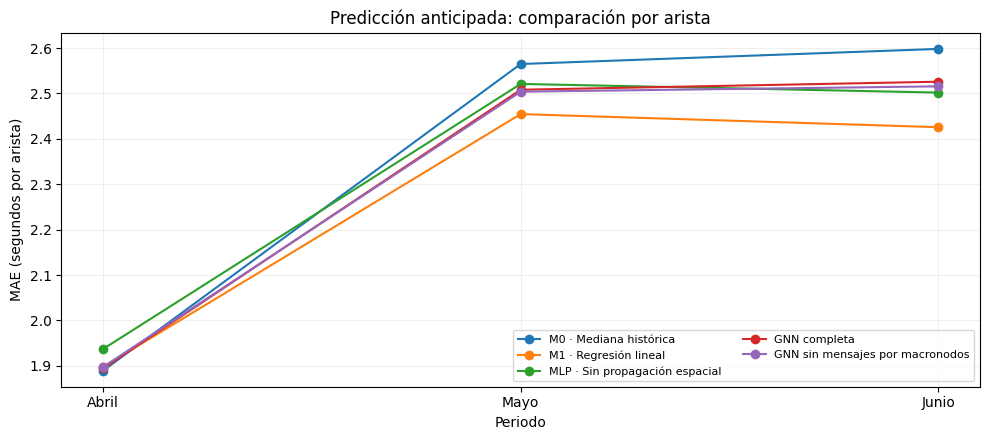

In [14]:

# Orden cronológico de los periodos de evaluación.
orden_periodos = [
    'abril_validacion',
    'mayo_diagnostico',
    'junio_diagnostico_no_ciego',
]

nombres_periodos = {
    'abril_validacion': 'Abril · validación',
    'mayo_diagnostico': 'Mayo · diagnóstico',
    'junio_diagnostico_no_ciego': 'Junio · no ciego',
}

# Etiquetas de presentación; se conservan los identificadores
# originales de los modelos para los cálculos y archivos CSV.
nombres_modelos = {
    'M0_mediana': 'M0 · Mediana histórica',
    'M1_temporal': 'M1 · Regresión lineal',
    'no_spatial': 'MLP · Sin propagación espacial',
    'full': 'GNN completa',
    'no_macro': 'GNN sin mensajes por macronodos',
}

# Construir una tabla de MAE para los cinco modelos.
# Cada valor resume todos los pares arista-instante del periodo.
resumen_arista = (
    results.loc[results['grupo'] == 'todas']
    .pivot(
        index='modelo',
        columns='periodo',
        values='MAE_seg'
    )
    .reindex(
        index=orden_modelos,
        columns=orden_periodos
    )
)

# Verificar que todos los modelos y periodos tienen resultados.
assert resumen_arista.notna().all().all()

# Mostrar nombres legibles sin alterar los datos originales.
display(
    resumen_arista
    .rename(
        index=nombres_modelos,
        columns=nombres_periodos
    )
    .round(4)
)

# Exportar los valores completos, conservando identificadores.
resumen_arista.to_csv(
    out / 'resumen_modelos_arista.csv'
)

# Comparación gráfica de los MAE mensuales.
fig, ax = plt.subplots(figsize=(10, 4.5))

for modelo in orden_modelos:
    ax.plot(
        ['Abril', 'Mayo', 'Junio'],
        resumen_arista.loc[
            modelo, orden_periodos
        ].to_numpy(),
        marker='o',
        label=nombres_modelos[modelo]
    )

ax.set(
    xlabel='Periodo',
    ylabel='MAE (segundos por arista)',
    title='Predicción anticipada: comparación por arista'
)

ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


### Interpretación de la comparación general

En abril, la referencia histórica M0 registra el menor MAE (1.8894 segundos por arista), seguida de la GNN completa (1.8942) y M1 (1.8977). Las diferencias entre estos modelos son pequeñas, mientras que el MLP presenta el mayor error del periodo. Cabe recordar que abril se utiliza para seleccionar la época de entrenamiento de las redes neuronales, por lo que estos resultados corresponden a validación y no a una evaluación independiente.

En mayo y junio, M1 obtiene los menores errores, con 2.4545 y 2.4256 segundos por arista, respectivamente. Los tres modelos neuronales mejoran la referencia M0 en ambos meses, pero ninguno supera a M1. Por tanto, las arquitecturas neuronales evaluadas no muestran una ventaja consistente frente a la regresión Ridge.

La comparación entre las variantes GNN tampoco muestra un beneficio sistemático de permitir el paso de mensajes por macronodos. La GNN completa obtiene un MAE ligeramente menor en abril, mientras que la variante sin esos mensajes presenta errores marginalmente menores en mayo y junio. Las comparaciones por jornada confirman que esta última variante obtiene menor error en la mayoría de los días de ambos meses, aunque las diferencias promedio siguen siendo pequeñas.

Estas observaciones corresponden a una única inicialización por configuración y a periodos examinados durante el desarrollo del proyecto. Por ello, no constituyen evidencia concluyente sobre la superioridad de una arquitectura.

### Diagnóstico de aumentos pronunciados

Como análisis complementario, se examinan las predicciones de junio correspondientes a observaciones cuyo tiempo real de desplazamiento fue al menos un 50 % superior a su mediana histórica. Este subconjunto comprende 24,438 pares arista-instante, equivalentes al 2.46 % de las observaciones evaluadas durante junio.

La condición se determina a partir de los tiempos efectivamente observados y se utiliza exclusivamente para evaluar las predicciones. Por tanto, este análisis no constituye una prueba de detección anticipada de aumentos pronunciados, ni permite identificar por sí mismo interrupciones o incidentes viales.


In [15]:

# Recuperar los errores de los cinco modelos para las observaciones
# de junio cuyo tiempo real fue al menos 50 % superior a M0.
# El subconjunto se identificó retrospectivamente con los tiempos
# observados y es exactamente el mismo para todos los modelos.

tabla_aumentos = (
    results.loc[
        (results['grupo'] == 'aumento_real_50pct_historico') &
        (results['periodo'] == 'junio_diagnostico_no_ciego'),
        ['modelo', 'MAE_seg', 'WAPE_pct']
    ]
    .set_index('modelo')
    .reindex(orden_modelos)
)

# Verificar que existen resultados para los cinco modelos.
assert len(tabla_aumentos) == 5
assert tabla_aumentos.notna().all().all()

# Mostrar etiquetas comprensibles y unidades explícitas.
display(
    tabla_aumentos
    .rename(
        index=nombres_modelos,
        columns={
            'MAE_seg': 'MAE (s/arista)',
            'WAPE_pct': 'WAPE (%)'
        }
    )
    .round(3)
)


,MAE (s/arista),WAPE (%)
modelo,,
M0 · Mediana histórica,35.196,52.360
M1 · Regresión lineal,33.486,49.817
MLP · Sin propagación espacial,34.808,51.783
GNN completa,34.364,51.123
GNN sin mensajes por macronodos,34.286,51.007


En este subconjunto, los cinco modelos presentan errores considerablemente mayores que en la evaluación general. M1 registra el menor MAE (33.486 segundos por arista) y WAPE (49.817 %), seguido de las dos variantes GNN. Aunque los modelos de aprendizaje reducen el error respecto de la mediana histórica M0, la magnitud de los errores sigue siendo elevada.

El diagnóstico evidencia dificultades para estimar los tiempos de desplazamiento cuando se producen aumentos pronunciados respecto del comportamiento habitual. Sin embargo, no constituye una prueba de detección anticipada de estos episodios: las observaciones se seleccionaron retrospectivamente a partir de sus tiempos reales, y un aumento del 50 % respecto de la mediana histórica no equivale necesariamente a una interrupción vial identificada.

### Alcance de los resultados

En mayo y junio, los cuatro modelos de aprendizaje reducen el MAE respecto de M0, pero la GNN implementada no obtiene una ventaja consistente frente al modelo lineal M1. El diagnóstico de aumentos pronunciados revela, además, limitaciones predictivas que no resultan evidentes al examinar únicamente el MAE global.

Estas conclusiones se limitan a las configuraciones y periodos evaluados. No permiten establecer cuál sería el desempeño ante interrupciones viales reales ni descartar que otras arquitecturas o formas de incorporar información espacial ofrezcan mejores resultados.



## 7. Traducción a matrices OD: evaluación complementaria

Los modelos de optimización de rutas considerados en el proyecto requieren tiempos de desplazamiento entre puntos de origen y destino (OD). Por ello, además de evaluar los errores de predicción por arista, examinamos cómo se trasladan esos errores a los tiempos mínimos de recorrido entre nodos de la red.

Para esta evaluación se consideran dos conjuntos de nodos de la misma red vial dirigida:

1. **13 macronodos funcionales**, que generan 156 pares OD ordenados, excluyendo los pares con el mismo origen y destino.
2. **20 nodos sensores**, seleccionados aleatoriamente con una semilla fija para garantizar su reproducibilidad, que generan 380 pares OD ordenados.

Ambos conjuntos constituyen instancias experimentales y no representan necesariamente las ubicaciones de clientes o instalaciones logísticas de un problema operativo real.

Se evalúan ocho instantes prefijados por jornada, correspondientes a las 08:00, 09:00, ..., 15:00. En cada instante se asignan a las 345 aristas los tiempos estimados por cada modelo y se aplica el algoritmo de Dijkstra para obtener los tiempos mínimos entre los pares OD seleccionados. Se repite el procedimiento utilizando los tiempos por arista derivados de las velocidades registradas para construir las matrices de referencia.

Las matrices OD se calculan con los pesos correspondientes a un instante específico, suponiendo que permanecen constantes durante el recorrido. Por tanto, este procedimiento no representa explícitamente la evolución del tráfico mientras un vehículo atraviesa las distintas aristas. Además, los tiempos OD de referencia son resultados calculados sobre nuestra red experimental, no observaciones independientes de recorridos completos realizados por vehículos.

El objetivo es evaluar la precisión de las matrices OD derivadas de las predicciones y su posible utilidad como entrada para un optimizador de rutas. No se ejecuta todavía el problema de ruteo de vehículos con ventanas de tiempo (VRPTW) ni se cuantifican beneficios operativos. Asimismo, las instancias y condiciones de evaluación difieren de las utilizadas anteriormente para Ridge con $K=32$, por lo que sus resultados no deben interpretarse como una comparación experimental directa.


In [16]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

# 1. Identificar los nodos de la red y convertir sus identificadores
# en índices numéricos para construir la matriz de adyacencia.
v_ids = nodes['node_id'].astype(str).tolist()
v_to_idx = {nodo: i for i, nodo in enumerate(v_ids)}

# Origen y destino de cada arista, conservando su dirección.
u = np.array(
    [v_to_idx[k] for k in edges['from'].astype(str)],
    dtype=np.int32
)
v = np.array(
    [v_to_idx[k] for k in edges['to'].astype(str)],
    dtype=np.int32
)

# No debe haber dos aristas con el mismo par origen-destino,
# pues la matriz dispersa combina entradas duplicadas.
assert len(v_to_idx) == len(v_ids)
assert not edges.duplicated(['from', 'to']).any()

# 2. Definir dos conjuntos experimentales de nodos OD.
macro_ids = (
    nodes.loc[nodes['node_type'] == 'interchange', 'node_id']
    .astype(str)
    .tolist()
)

sensor_ids = (
    nodes.loc[nodes['node_type'] == 'sensor', 'node_id']
    .astype(str)
    .tolist()
)

# Muestra fija de 20 sensores, sin reemplazo.
rng = np.random.default_rng(2026)
sensor20 = sorted(
    rng.choice(sensor_ids, size=20, replace=False).tolist()
)

SETS = {
    'macronodos_13': macro_ids,
    'sensores_20': sensor20
}

assert len(macro_ids) == 13
assert len(sensor20) == 20
assert len(set(sensor20)) == 20

# 3. Evaluar un instante por hora, de 08:00 a 15:00.
# Los datos originales tienen intervalos de cinco minutos:
# cada 12 posiciones corresponde a una hora.
SLOTS = np.arange(0, 96, 12, dtype=int)
assert len(SLOTS) == 8

def od_vector(weights, selected):
    """
    Calcular los tiempos mínimos entre pares OD ordenados.

    weights: tiempos de las 345 aristas para un instante, en minutos.
    selected: identificadores de los nodos origen-destino.

    Devuelve un vector de tiempos OD en minutos, excluyendo
    los pares donde el origen coincide con el destino.
    """
    weights = np.asarray(weights)

    assert weights.shape == (len(edges),)
    assert np.isfinite(weights).all() and (weights > 0).all()

    # Construir el grafo vial dirigido completo, asignando a
    # cada arista su tiempo de desplazamiento estimado u observado.
    graph = csr_matrix(
        (weights, (u, v)),
        shape=(len(v_ids), len(v_ids))
    )

    # Seleccionar los orígenes y destinos de interés.
    idx = np.array([v_to_idx[nodo] for nodo in selected])

    # Dijkstra obtiene las rutas mínimas sobre toda la red,
    # aunque solo se conservan los tiempos entre nodos seleccionados.
    times = dijkstra(
        graph,
        directed=True,
        indices=idx
    )[:, idx]

    # Excluir la diagonal: no evaluamos viajes de un nodo a sí mismo.
    mask = ~np.eye(len(idx), dtype=bool)
    return times[mask]


# 4. Comprobar que todos los pares OD seleccionados son alcanzables.
# Los pesos unitarios permiten verificar conectividad sin depender
# de las predicciones de un modelo particular.
for nombre, seleccion in SETS.items():
    prueba = od_vector(
        np.ones(len(edges), dtype=float),
        seleccion
    )
    assert np.isfinite(prueba).all()

print(
    'Pares OD:',
    {nombre: len(sel) * (len(sel) - 1)
     for nombre, sel in SETS.items()},
    '| Instantes por jornada:', len(SLOTS)
)


Pares OD: {'macronodos_13': 156, 'sensores_20': 380} | Instantes por jornada: 8


In [17]:

# Evaluar los tiempos OD derivados de los cinco modelos.
# Cada matriz se calcula sobre la red dirigida completa,
# utilizando los tiempos de arista correspondientes a un instante.

od_rows = []
error_diario_od = []

for periodo, datos in periodos:

    # 1. Generar los tiempos de arista estimados por cada modelo.
    # Dimensiones: jornadas x 96 instantes x 345 aristas.
    pred = {'M0_mediana': datos['b']}

    for modo, modelo in models.items():
        pred[modo] = prediction(modelo, datos)

    # M1 utiliza solo información disponible antes del pronóstico.
    pred_m1 = []

    for dia in datos['dates']:
        entradas = inputs_disponibles_al_corte(dia)
        assert entradas is not None, f'Sin entradas para {dia}'

        residuo = (
            expanded_features(entradas, 'M1_temporal')
            @ theta_M1
        )

        tiempo_estimado = entradas['baseline'] * np.exp(
            np.clip(residuo, -4, 4)
        )

        pred_m1.append(tiempo_estimado)

    pred['M1_temporal'] = np.stack(pred_m1).astype('float32')

    # Verificar que todos los modelos tienen predicciones completas.
    assert set(pred) == set(orden_modelos)
    assert all(
        p.shape == datos['truth'].shape
        for p in pred.values()
    )

    # 2. Evaluar por separado las dos instancias OD.
    for instancia, seleccion in SETS.items():

        errores = {modelo: [] for modelo in orden_modelos}
        tiempos_reales = []

        for j, dia in enumerate(datos['dates']):

            # Acumular errores de los ocho instantes de esta jornada.
            errores_dia = {
                modelo: [] for modelo in orden_modelos
            }

            for slot in SLOTS:

                # Matriz OD de referencia: rutas mínimas calculadas
                # con los tiempos de arista derivados de las
                # velocidades efectivamente registradas.
                od_real = od_vector(
                    datos['truth'][j, slot],
                    seleccion
                )

                assert np.isfinite(od_real).all()
                assert (od_real > 0).all()

                tiempos_reales.append(od_real)

                # Cada modelo genera su propia matriz OD mediante
                # Dijkstra, usando sus tiempos de arista estimados.
                for modelo in orden_modelos:

                    od_estimado = od_vector(
                        pred[modelo][j, slot],
                        seleccion
                    )

                    assert np.isfinite(od_estimado).all()
                    assert (od_estimado > 0).all()

                    error = np.abs(od_estimado - od_real)

                    errores[modelo].append(error)
                    errores_dia[modelo].append(error)

            # 3. MAE OD por jornada, calculado sobre los ocho
            # instantes y todos los pares OD de la instancia.
            for modelo in orden_modelos:
                error_jornada = np.concatenate(
                    errores_dia[modelo]
                )

                error_diario_od.append({
                    'periodo': periodo,
                    'nodos': instancia,
                    'dia': dia,
                    'modelo': modelo,
                    'MAE_OD_seg': float(
                        60 * error_jornada.mean()
                    )
                })

        # 4. Métricas agregadas por periodo, instancia y modelo.
        # Los tiempos OD están en minutos y se convierten
        # a segundos para MAE y P95.
        real = np.concatenate(tiempos_reales)

        for modelo in orden_modelos:
            error = np.concatenate(errores[modelo])

            assert error.shape == real.shape

            od_rows.append({
                'periodo': periodo,
                'instancia': instancia,
                'modelo': modelo,
                'n_dias': len(datos['dates']),
                'cortes_dia': len(SLOTS),
                'n_pares': len(seleccion) * (len(seleccion) - 1),
                'MAE_OD_seg': float(60 * error.mean()),
                'P95_OD_seg': float(
                    60 * np.quantile(error, 0.95)
                ),
                'WAPE_OD_pct': float(
                    100 * error.sum() / real.sum()
                )
            })

# 5. Guardar métricas agregadas y errores diarios.
od_df = pd.DataFrame(od_rows)
od_daily = pd.DataFrame(error_diario_od)

assert len(od_df) == 3 * 2 * 5
assert len(od_daily) == 90 * 2 * 5

od_df.to_csv(
    out / 'evaluacion_OD_ultimo_avance.csv',
    index=False
)

od_daily.to_csv(
    out / 'evaluacion_OD_por_dia.csv',
    index=False
)

# 6. Presentar el MAE OD en orden cronológico.
tabla_od = (
    od_df.pivot(
        index=['periodo', 'instancia'],
        columns='modelo',
        values='MAE_OD_seg'
    )
    .reindex(
        index=pd.MultiIndex.from_product(
            [orden_periodos, list(SETS)],
            names=['periodo', 'instancia']
        ),
        columns=orden_modelos
    )
)

assert tabla_od.notna().all().all()

print('Evaluación OD concluida. MAE en segundos:')
display(
    tabla_od
    .rename(columns=nombres_modelos)
    .round(3)
)


Evaluación OD concluida. MAE en segundos:


modelo                                    M0 · Mediana histórica  \
periodo                    instancia                               
abril_validacion           macronodos_13                  26.709   
                           sensores_20                    35.465   
mayo_diagnostico           macronodos_13                  37.315   
                           sensores_20                    46.816   
junio_diagnostico_no_ciego macronodos_13                  38.150   
                           sensores_20                    47.692   

modelo                                    M1 · Regresión lineal  \
periodo                    instancia                              
abril_validacion           macronodos_13                 26.840   
                           sensores_20                   35.668   
mayo_diagnostico           macronodos_13                 33.030   
                           sensores_20                   41.479   
junio_diagnostico_no_ciego macronodos_13                 32.673   
                           sensores_20                   41.308   

modelo                                    MLP · Sin propagación espacial  \
periodo                    instancia                                       
abril_validacion           macronodos_13                          27.400   
                           sensores_20                            36.903   
mayo_diagnostico           macronodos_13                          34.631   
                           sensores_20                            43.610   
junio_diagnostico_no_ciego macronodos_13                          34.422   
                           sensores_20                            43.069   

modelo                                    GNN completa  \
periodo                    instancia                     
abril_validacion           macronodos_13        26.518   
                           sensores_20          35.228   
mayo_diagnostico           macronodos_13        34.910   
                           sensores_20          43.848   
junio_diagnostico_no_ciego macronodos_13        35.662   
                           sensores_20          44.944   

modelo                                    GNN sin mensajes por macronodos  
periodo                    instancia                                       
abril_validacion           macronodos_13                           26.529  
                           sensores_20                             35.233  
mayo_diagnostico           macronodos_13                           34.590  
                           sensores_20                             43.475  
junio_diagnostico_no_ciego macronodos_13                           35.217  
                           sensores_20                             44.447

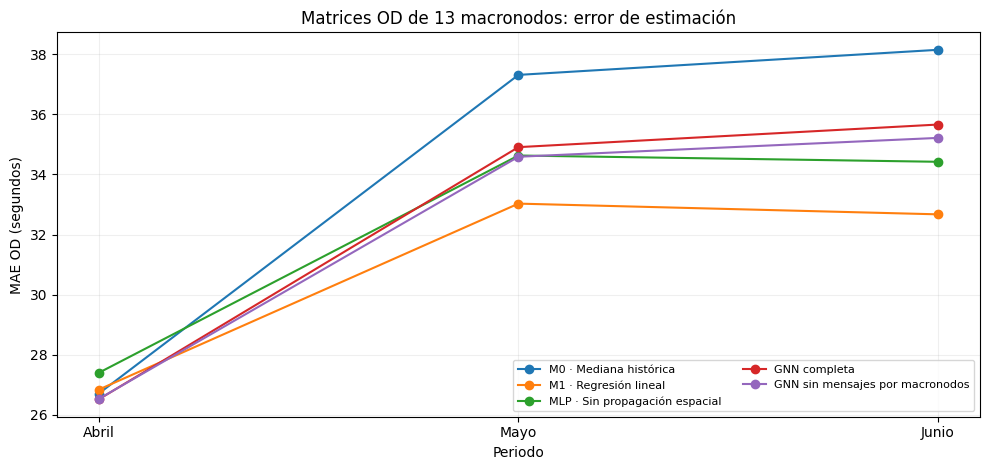

In [18]:
# Comparar el MAE de los tiempos OD para la instancia
# de 13 macronodos, considerando los tres periodos evaluados.
# Cada valor resume ocho instantes por jornada y 156 pares OD.

macro = od_df.loc[
    od_df['instancia'] == 'macronodos_13'
]

# Organizar los valores de todos los modelos en orden cronológico.
resumen_macro = (
    macro.pivot(
        index='modelo',
        columns='periodo',
        values='MAE_OD_seg'
    )
    .reindex(
        index=orden_modelos,
        columns=orden_periodos
    )
)

assert resumen_macro.notna().all().all()

# Mostrar las tendencias del error de los cinco modelos.
fig, ax = plt.subplots(figsize=(10, 4.8))

for modelo in orden_modelos:
    ax.plot(
        ['Abril', 'Mayo', 'Junio'],
        resumen_macro.loc[modelo, orden_periodos].to_numpy(),
        marker='o',
        label=nombres_modelos[modelo]
    )

ax.set(
    xlabel='Periodo',
    ylabel='MAE OD (segundos)',
    title='Matrices OD de 13 macronodos: error de estimación'
)

ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()



### Interpretación de los resultados OD

En abril, la GNN completa obtiene el menor MAE de tiempos OD en ambas instancias: 26.518 segundos para los 13 macronodos y 35.228 segundos para los 20 sensores. La diferencia respecto de la variante sin mensajes por macronodos es muy pequeña. Estos resultados corresponden al periodo de validación, aunque la selección de las épocas de entrenamiento se realizó utilizando el MAE por arista, no el error OD.

En mayo y junio, M1 registra el menor MAE en ambas instancias. Para los 13 macronodos, obtiene errores de 33.030 y 32.673 segundos, respectivamente; para los 20 sensores, de 41.479 y 41.308 segundos. Los modelos neuronales mejoran la referencia histórica M0, pero no superan a M1 durante estos periodos.

La evaluación OD confirma que las diferencias entre modelos observadas a nivel de arista también tienen implicaciones para los tiempos mínimos de recorrido entre nodos. Sin embargo, la clasificación de los modelos puede cambiar, ya que los errores individuales de las aristas no se trasladan directamente a los tiempos calculados mediante Dijkstra.

### Alcance de la evaluación OD

Los resultados corresponden a tiempos mínimos calculados sobre la red experimental, utilizando pesos fijos para cada instante. No representan mediciones independientes de viajes completos ni permiten determinar si las rutas seleccionadas con los tiempos pronosticados serían las más adecuadas bajo las condiciones efectivamente observadas.

Por tanto, esta evaluación permite cuantificar la precisión de las matrices OD derivadas de las predicciones, pero todavía no demuestra mejoras en la solución de un problema de optimización de rutas. Esa integración constituye una etapa posterior del proyecto.


### Magnitud de la mejora de M1 frente a la referencia histórica

Como complemento de la comparación anterior, se calcula cuánto disminuye el MAE OD de M1 respecto de M0 en mayo y junio, en segundos y en porcentaje. Un valor positivo indica que M1 presenta un menor error de predicción.

Los cálculos utilizan los valores completos de `tabla_od`; el redondeo se aplica únicamente al mostrar los resultados. Se trata de una comparación descriptiva de precisión predictiva, no de una estimación de ahorro de tiempo de viaje ni de beneficios del optimizador.

In [19]:
# Resumir los errores OD ya calculados, sin repetir predicciones ni entrenamientos.
# Utilizar los valores completos: redondear antes de restar introduce diferencias.
filas_mejora = []

for periodo, mes in [
    ('mayo_diagnostico', 'Mayo'),
    ('junio_diagnostico_no_ciego', 'Junio'),
]:
    for instancia, etiqueta in [
        ('macronodos_13', '13 macronodos'),
        ('sensores_20', '20 sensores'),
    ]:
        m0, m1 = tabla_od.loc[
            (periodo, instancia), ['M0_mediana', 'M1_temporal']
        ]
        diferencia = float(m0 - m1)

        filas_mejora.append({
            'Periodo': mes,
            'Instancia OD': etiqueta,
            'Reducción MAE (s)': diferencia,
            'Reducción MAE (%)': 100 * diferencia / float(m0),
        })

resumen_mejora = pd.DataFrame(filas_mejora)
assert len(resumen_mejora) == 4
assert (resumen_mejora['Reducción MAE (s)'] > 0).all()
display(resumen_mejora.round(2))

,Periodo,Instancia OD,Reducción MAE (s),Reducción MAE (%)
0,Mayo,13 macronodos,4.29,11.48
1,Mayo,20 sensores,5.34,11.40
2,Junio,13 macronodos,5.48,14.36
3,Junio,20 sensores,6.38,13.39


## 8. Función de inferencia para nuevas jornadas

Las secciones anteriores evaluaron los modelos utilizando observaciones históricas de abril a junio de 2017. Para facilitar su aplicación a nuevas jornadas, se define la función `predecir_aristas_sin_futuro()`, que reúne en una misma interfaz los procedimientos de predicción de los cinco modelos.

La función recibe las características construidas mediante `inputs_disponibles_al_corte()` y utiliza los parámetros previamente ajustados para estimar los tiempos de desplazamiento de las 345 aristas en los 96 instantes de la jornada objetivo. No modifica los modelos ni introduce un procedimiento predictivo diferente del utilizado en las evaluaciones anteriores.

El código incorpora comprobaciones de consistencia sobre las fechas, las dimensiones de las entradas y la equivalencia de las predicciones para una jornada previamente evaluada. Finalmente, se utiliza la función para generar estimaciones correspondientes al 1 de julio de 2017, fecha posterior al periodo observado, como preparación para la visualización y exportación de resultados.


In [20]:

# 1. Verificar que las particiones temporales sean consecutivas
# y no se superpongan. Las medianas históricas se calculan
# exclusivamente con registros de enero a marzo de 2017.

assert max(pd.to_datetime(train['dates'])) < min(pd.to_datetime(val['dates']))
assert max(pd.to_datetime(val['dates'])) < min(pd.to_datetime(may['dates']))
assert max(pd.to_datetime(may['dates'])) < min(pd.to_datetime(june['dates']))
assert reference.index.max() < pd.Timestamp('2017-04-01')

# 2. Comprobar el corte de información para tres jornadas:
# dos fechas de validación y una posterior al periodo observado.

fechas_comprobacion = [
    pd.Timestamp('2017-04-17'),
    pd.Timestamp('2017-04-22'),
    pd.Timestamp('2017-07-01')
]

for dia in fechas_comprobacion:
    entrada = inputs_disponibles_al_corte(dia)

    assert entrada is not None

    # El pronóstico se emite a las 18:00 del día anterior.
    assert entrada['issue_at'] == entrada['cut'] + pd.Timedelta(minutes=5)
    assert entrada['issue_at'] == dia - pd.Timedelta(hours=6)

    # Todos los instantes objetivo son posteriores a la emisión.
    assert entrada['targets'].min() > entrada['issue_at']

    # Cada jornada comprende 96 instantes y 345 aristas,
    # con diez características disponibles por arista.
    assert entrada['features'].shape == (96, len(edges), 10)
    assert np.isfinite(entrada['features']).all()


# 3. Definir una interfaz común de predicción.
# Recibe entradas históricas y un modelo previamente ajustado.
# Devuelve tiempos de desplazamiento en minutos.

def predecir_aristas_sin_futuro(entrada, modelo):
    """Genera los tiempos estimados para 96 instantes y 345 aristas."""

    referencia = entrada['baseline']

    if modelo == 'M0_mediana':
        estimado = referencia.copy()

    elif modelo == 'M1_temporal':
        residuo = entrada['features'] @ theta_M1
        estimado = referencia * np.exp(np.clip(residuo, -4, 4))

    elif modelo in {'GNN_completa', 'MLP', 'GNN_sin_macro'}:

        equivalencias = {
            'GNN_completa': 'full',
            'MLP': 'no_spatial',
            'GNN_sin_macro': 'no_macro'
        }

        modelo_entrenado = models[equivalencias[modelo]]
        modelo_entrenado.eval()

        with torch.no_grad():
            caracteristicas = torch.from_numpy(
                entrada['features'][None]
            )
            residuo = modelo_entrenado(caracteristicas).numpy()[0]

        estimado = referencia * np.exp(residuo)

    else:
        raise ValueError(f'Modelo desconocido: {modelo}')

    # Comprobar dimensiones y validez de los tiempos estimados.
    assert estimado.shape == (96, len(edges))
    assert np.isfinite(estimado).all()
    assert (estimado > 0).all()

    return np.asarray(estimado, dtype='float32')


# 4. Comprobar que la nueva interfaz reproduce las predicciones
# utilizadas durante la evaluación de abril.

fecha = '2017-04-17'

entrada = inputs_disponibles_al_corte(fecha)
ejemplo = daily_example(fecha)

assert entrada is not None and ejemplo is not None

# La función de evaluación agrega observaciones reales,
# pero debe construir exactamente las mismas características.
assert np.array_equal(
    entrada['features'],
    ejemplo['features']
)

# Comprobación de M0.
assert np.allclose(
    predecir_aristas_sin_futuro(entrada, 'M0_mediana'),
    ejemplo['baseline']
)

# Comprobación de M1.
residuo_m1 = (
    expanded_features(ejemplo, 'M1_temporal') @ theta_M1
)
esperado_m1 = ejemplo['baseline'] * np.exp(
    np.clip(residuo_m1, -4, 4)
)

assert np.allclose(
    predecir_aristas_sin_futuro(entrada, 'M1_temporal'),
    esperado_m1,
    rtol=1e-5,
    atol=1e-5
)

# Comprobación de las tres redes neuronales.
indice_dia = val['dates'].index(fecha)

for modo, nombre in [
    ('no_spatial', 'MLP'),
    ('full', 'GNN_completa'),
    ('no_macro', 'GNN_sin_macro')
]:
    esperado = prediction(models[modo], val)[indice_dia]
    obtenido = predecir_aristas_sin_futuro(entrada, nombre)

    assert np.allclose(
        obtenido, esperado,
        rtol=1e-5,
        atol=1e-5
    )


# 5. Verificar que la interfaz admite una jornada sin
# observaciones de tráfico del día objetivo en el dataset.

entrada_julio = inputs_disponibles_al_corte('2017-07-01')

assert entrada_julio is not None
assert not entrada_julio['targets'].isin(Y.index).any()

for nombre in [
    'M0_mediana',
    'M1_temporal',
    'MLP',
    'GNN_completa',
    'GNN_sin_macro'
]:
    estimado = predecir_aristas_sin_futuro(
        entrada_julio, nombre
    )
    assert estimado.shape == (96, len(edges))

print('Función de inferencia definida y comprobaciones completadas.')


Función de inferencia definida y comprobaciones completadas.



## 9. Perfiles horarios de predicción en jornadas de validación

Además de las métricas agregadas, se examina cómo evolucionan los tiempos de desplazamiento a lo largo de dos jornadas de validación: el lunes 17 y el sábado 22 de abril de 2017. El objetivo es comparar los perfiles horarios observados con los estimados por M0, M1 y la GNN completa, e ilustrar las diferencias entre un día laborable y uno de fin de semana.

Para facilitar la visualización, se seleccionan 20 aristas de corredor con mayor variación relativa de sus medianas históricas. La selección se realiza exclusivamente con información de enero a marzo, sin utilizar las observaciones de abril.

Las gráficas representan, para cada instante entre las 08:00 y las 15:55, el promedio de los tiempos de desplazamiento de estas 20 aristas. Los valores observados se incorporan únicamente para comparar las predicciones con el comportamiento registrado.

También se identifica el instante en que cada curva alcanza su valor máximo dentro del intervalo analizado. Estos resultados corresponden a una muestra seleccionada de aristas y no deben interpretarse como indicadores de congestión de toda la red vial ni como una identificación de las horas pico del día completo.


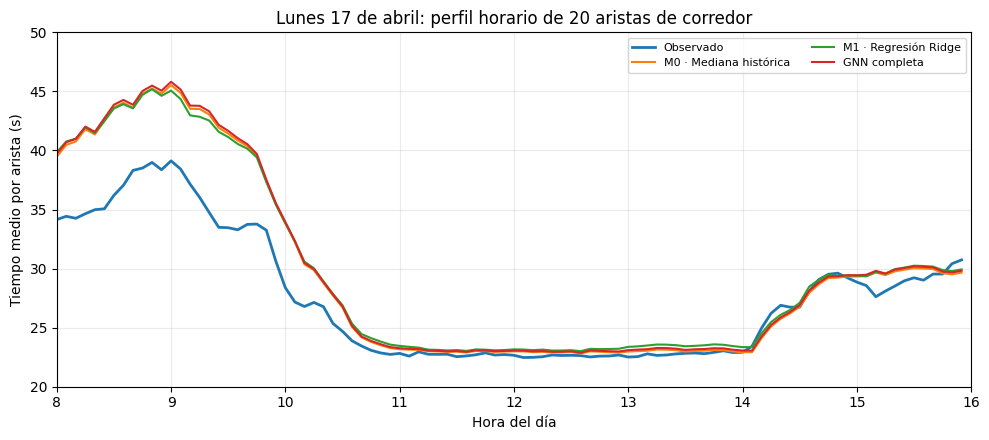

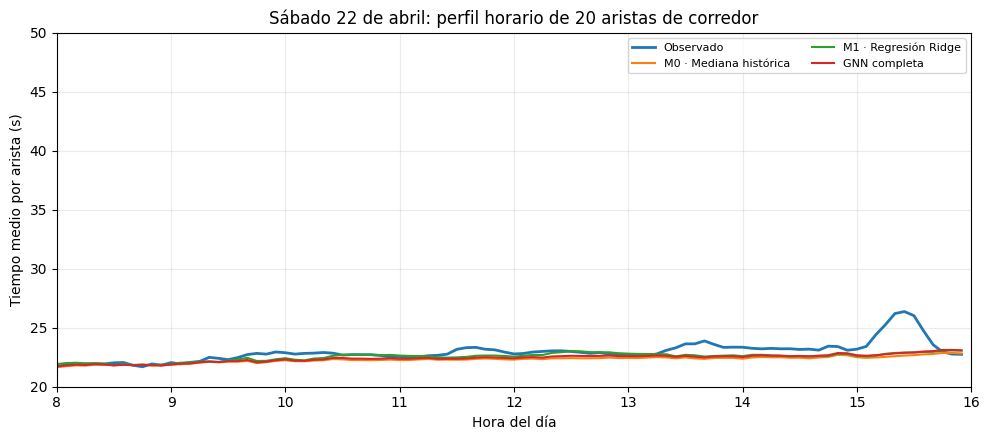

,Fecha,Curva,Hora del máximo,Tiempo medio máximo (s)
0,2017-04-17,Observado,09:00,39.12
1,2017-04-17,M0 · Mediana histórica,09:00,45.54
2,2017-04-17,M1 · Regresión Ridge,08:50,45.19
3,2017-04-17,GNN completa,09:00,45.81
4,2017-04-22,Observado,15:25,26.37
5,2017-04-22,M0 · Mediana histórica,15:45,22.87
6,2017-04-22,M1 · Regresión Ridge,15:50,23.08
7,2017-04-22,GNN completa,15:50,23.12


In [21]:

# 1. Seleccionar 20 aristas de corredor utilizando exclusivamente
# las medianas históricas calculadas con enero-marzo de 2017.
# Se consideran perfiles de referencia de un lunes y un sábado.

dias_patron = [
    pd.date_range('2017-03-20 08:00', periods=96, freq='5min'),
    pd.date_range('2017-03-25 08:00', periods=96, freq='5min')
]

patron = np.concatenate(
    [historical_median(t) for t in dias_patron],
    axis=0
)

# Medir la variación relativa de las medianas históricas.
# El criterio utiliza los percentiles 90 y 10, normalizados
# por la mediana de cada arista.
q90 = np.quantile(patron, 0.90, axis=0)
q10 = np.quantile(patron, 0.10, axis=0)

variacion = (
    (q90 - q10)
    / np.maximum(np.median(patron, axis=0), 1e-6)
)

# Restringir la selección a aristas de corredor.
indices_corredor = np.flatnonzero(
    (edges['edge_type'] == 'corridor').to_numpy()
)

seleccion = indices_corredor[
    np.argsort(
        -variacion[indices_corredor],
        kind='stable'
    )[:20]
]

assert len(seleccion) == 20
assert len(set(seleccion)) == 20


# 2. Comparar perfiles observados y estimados para
# dos jornadas previamente definidas de validación.
jornadas = [
    ('2017-04-17', 'Lunes 17 de abril'),
    ('2017-04-22', 'Sábado 22 de abril')
]

picos = []

for fecha, etiqueta in jornadas:

    # Las predicciones se construyen con información histórica.
    # Los tiempos reales se recuperan por separado para comparar.
    entrada = inputs_disponibles_al_corte(fecha)
    evaluacion = daily_example(fecha)

    assert entrada is not None
    assert evaluacion is not None
    assert pd.Timestamp(fecha) in pd.to_datetime(val['dates'])

    curvas = {
        'Observado': evaluacion['truth'],
        'M0 · Mediana histórica':
            predecir_aristas_sin_futuro(entrada, 'M0_mediana'),
        'M1 · Regresión Ridge':
            predecir_aristas_sin_futuro(entrada, 'M1_temporal'),
        'GNN completa':
            predecir_aristas_sin_futuro(entrada, 'GNN_completa')
    }

    # 3. Calcular el tiempo medio de las 20 aristas seleccionadas
    # para cada uno de los 96 instantes de la jornada.
    # Los tiempos originales están en minutos; se convierten a segundos.
    horas = (
        entrada['targets'].hour
        + entrada['targets'].minute / 60
    )

    fig, ax = plt.subplots(figsize=(10, 4.5))

    for nombre, tiempos in curvas.items():

        assert tiempos.shape == (96, len(edges))

        promedio_seg = 60 * tiempos[:, seleccion].mean(axis=1)

        ax.plot(
            horas,
            promedio_seg,
            label=nombre,
            linewidth=2 if nombre == 'Observado' else 1.5
        )

        # Registrar el instante de mayor tiempo medio
        # dentro del intervalo 08:00–15:55.
        indice_max = int(np.argmax(promedio_seg))

        picos.append({
            'fecha': fecha,
            'curva': nombre,
            'hora_maxima_dentro_del_horizonte':
                entrada['targets'][indice_max].strftime('%H:%M'),
            'tiempo_promedio_maximo_seg':
                float(promedio_seg[indice_max])
        })

    # 4. Presentar y guardar la gráfica de cada jornada.
    ax.set(
        xlabel='Hora del día',
        ylabel='Tiempo medio por arista (s)',
        title=f'{etiqueta}: perfil horario de 20 aristas de corredor',
        xlim=(8, 16)
    )

    # Misma escala vertical para ambas jornadas.
    # Se acota al rango de interés para facilitar la comparación
    # sin exagerar las diferencias del sábado.
    ax.set_ylim(20, 50)
    ax.set_yticks(np.arange(20, 51, 5))

    ax.set_xticks(np.arange(8, 17))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=2)

    fig.tight_layout()
    fig.savefig(
        out / f'perfil_horario_{fecha}.png',
        dpi=150
    )
    plt.show()


# 5. Resumir los máximos observados y estimados
# dentro del intervalo analizado.
picos_df = pd.DataFrame(picos)

picos_df.to_csv(
    out / 'perfiles_horarios_validacion.csv',
    index=False
)

display(
    picos_df
    .rename(columns={
        'fecha': 'Fecha',
        'curva': 'Curva',
        'hora_maxima_dentro_del_horizonte': 'Hora del máximo',
        'tiempo_promedio_maximo_seg': 'Tiempo medio máximo (s)'
    })
    .round(2)
)



### Interpretación de los perfiles horarios

En el lunes 17 de abril, los tres modelos reproducen aproximadamente la evolución general del perfil observado, caracterizado por tiempos mayores durante la mañana y un descenso posterior. Sin embargo, sobreestiman los tiempos de desplazamiento en las primeras horas. El máximo observado es de 39.12 segundos a las 09:00, frente a máximos estimados de entre 45.19 y 45.81 segundos.

Para el sábado 22 de abril, el máximo observado alcanza 26.37 segundos a las 15:25, mientras que los modelos estiman máximos menores, entre 22.87 y 23.12 segundos, que ocurren aproximadamente 20–25 minutos después.

Estos ejemplos muestran que los modelos pueden aproximar algunos patrones horarios sin reproducir necesariamente la magnitud y el momento de sus máximos en jornadas particulares. Los resultados son ilustrativos, pues corresponden únicamente a dos jornadas de validación y a una selección de 20 aristas de corredor. Asimismo, los máximos identificados se limitan al horizonte comprendido entre las 08:00 y las 15:55.



## 10. Exportación experimental de matrices OD para una nueva jornada

Como paso hacia la integración con el optimizador de rutas de Berth y Trigos, se implementa un procedimiento para convertir los tiempos de desplazamiento pronosticados por arista en matrices origen-destino (OD) y exportarlas en formato CSV. Esta salida constituye una propuesta experimental de intercambio de información, cuyo formato definitivo deberá acordarse con los responsables del optimizador.

La demostración utiliza el **1 de julio de 2017**, jornada inmediatamente posterior al periodo cubierto por los datos disponibles. Se simula la emisión del pronóstico el **30 de junio a las 18:00**, utilizando observaciones de tráfico disponibles hasta las 17:55. Como no se dispone de los tiempos observados del 1 de julio, las predicciones pueden generarse, pero no evaluarse mediante MAE. Se trata de una simulación histórica del procedimiento de inferencia, no de un pronóstico del tráfico actual.

Para cada uno de los 96 instantes comprendidos entre las 08:00 y las 15:55, separados por intervalos de cinco minutos, se calculan mediante Dijkstra los tiempos mínimos de recorrido entre los **13 macronodos experimentales**. Esto produce **96 matrices OD dirigidas de 13 × 13 por modelo**, con 156 pares origen-destino distintos por instante, excluyendo los recorridos de un nodo hacia sí mismo.

La selección de los 13 macronodos responde al propósito de esta demostración y no constituye una restricción del procedimiento. Es posible construir matrices OD para otros conjuntos de puntos representados por nodos de la red vial, sin modificar ni volver a entrenar los modelos predictivos. Para incorporar ubicaciones situadas en el interior de las aristas sería necesario definir previamente sus puntos de acceso y su correspondencia con la red.

Se consideran tres modelos para ilustrar la exportación: M0 (mediana histórica), M1 (regresión Ridge) y GNN completa. Esto permite generar y contrastar los tiempos estimados mediante modelos de distinta complejidad, sin establecer que deban integrarse simultáneamente ni que alguno haya sido seleccionado definitivamente para una aplicación operativa.

Para cada modelo se generan:

1. Un archivo CSV con los tiempos pronosticados de las 345 aristas en los 96 instantes.
2. Un archivo CSV en formato largo con los tiempos OD, los identificadores de origen y destino, la fecha y hora de emisión, el instante objetivo y el modelo utilizado.
3. Dos ejemplos de matrices cuadradas de 13 × 13, correspondientes a las 08:00 y las 12:00, expresadas en minutos y con diagonal nula.

Los macronodos utilizados son puntos funcionales de la red experimental y no representan todavía las ubicaciones logísticas de una instancia real. Además, las matrices se calculan suponiendo que los tiempos por arista permanecen constantes durante cada recorrido, como en la evaluación de la sección 7.

Esta exportación demuestra que es posible generar archivos estructurados a partir de pronósticos anticipados, pero **no constituye una integración probada con el optimizador**. Para avanzar hacia ella será necesario acordar los puntos logísticos y su correspondencia con la red, los identificadores, las unidades, el formato de intercambio y la manera en que las matrices se incorporarán al procedimiento de optimización.



In [22]:

# 1. Definir la jornada de demostración y construir sus entradas.
# El dataset termina el 30 de junio de 2017; no contiene
# observaciones de la jornada que se desea pronosticar.
DIA_EXPORTACION = '2017-07-01'

entrada_futura = inputs_disponibles_al_corte(DIA_EXPORTACION)
assert entrada_futura is not None

assert entrada_futura['issue_at'] == pd.Timestamp('2017-06-30 18:00')
assert entrada_futura['cut'] == pd.Timestamp('2017-06-30 17:55')
assert not entrada_futura['targets'].isin(Y.index).any()

# 2. Preparar los archivos y los puntos OD de la demostración.
carpeta_export = out / 'exportacion_od_experimental'
carpeta_export.mkdir(parents=True, exist_ok=True)

modos_exportacion = [
    'M0_mediana',
    'M1_temporal',
    'GNN_completa'
]

ids_od = SETS['macronodos_13']

# Pares dirigidos, excluyendo origen = destino.
# Su orden coincide con el vector que devuelve od_vector().
pares_od = [
    (origen, destino)
    for origen in ids_od
    for destino in ids_od
    if origen != destino
]

assert len(ids_od) == 13
assert len(set(ids_od)) == 13
assert len(pares_od) == 156

archivos = []
muestra_od = None

for modo in modos_exportacion:

    # 3. Pronosticar los tiempos de las 345 aristas
    # para los 96 instantes de la jornada.
    estimados = predecir_aristas_sin_futuro(
        entrada_futura, modo
    )

    assert estimados.shape == (96, len(edges))
    assert np.isfinite(estimados).all()
    assert (estimados > 0).all()

    # Exportar los tiempos por arista (en minutos).
    aristas_df = pd.DataFrame(
        estimados,
        index=entrada_futura['targets'],
        columns=edge_ids
    )
    aristas_df.index.name = 'fecha_hora_objetivo'

    archivo_aristas = (
        carpeta_export / f'aristas_{DIA_EXPORTACION}_{modo}.csv'
    )
    aristas_df.to_csv(archivo_aristas)
    archivos.append(str(archivo_aristas))

    # 4. Convertir los tiempos por arista en tiempos OD.
    # Para cada instante se utiliza Dijkstra sobre la red completa.
    registros = []
    vectores_od = []

    for instante, pesos in zip(
        entrada_futura['targets'], estimados
    ):
        od = od_vector(pesos, ids_od)

        assert len(od) == len(pares_od)
        assert np.isfinite(od).all()
        assert (od > 0).all()

        vectores_od.append(od)

        for (origen, destino), duracion in zip(pares_od, od):
            registros.append({
                'fecha_hora_emision':
                    entrada_futura['issue_at'].isoformat(),
                'fecha_hora_objetivo': instante.isoformat(),
                'origen': origen,
                'destino': destino,
                'tiempo_viaje_min': float(duracion),
                'modelo': modo
            })

    # Archivo largo: 96 instantes x 156 pares OD.
    od_df_export = pd.DataFrame(registros)

    assert len(od_df_export) == 96 * 156
    assert od_df_export['fecha_hora_objetivo'].nunique() == 96

    archivo_od = (
        carpeta_export / f'OD_{DIA_EXPORTACION}_{modo}.csv'
    )
    od_df_export.to_csv(archivo_od, index=False)
    archivos.append(str(archivo_od))

    # Conservar una muestra de M1 para mostrarla al final.
    if modo == 'M1_temporal':
        muestra_od = od_df_export.head(8).copy()

    # 5. Exportar matrices cuadradas de ejemplo
    # correspondientes a las 08:00 y las 12:00.
    for posicion in [0, 48]:

        matriz = np.zeros(
            (len(ids_od), len(ids_od)),
            dtype='float64'
        )

        mascara = ~np.eye(len(ids_od), dtype=bool)
        matriz[mascara] = vectores_od[posicion]

        # Comprobar que los tiempos y los pares OD corresponden
        # exactamente a los registrados en el archivo largo.
        inicio = posicion * len(pares_od)
        fin = inicio + len(pares_od)
        filas = od_df_export.iloc[inicio:fin]

        assert list(zip(
            filas['origen'], filas['destino']
        )) == pares_od

        assert np.allclose(
            matriz[mascara],
            filas['tiempo_viaje_min'].to_numpy()
        )

        # Conservar identificadores de origen y destino.
        matriz_df = pd.DataFrame(
            matriz,
            index=ids_od,
            columns=ids_od
        )
        matriz_df.index.name = 'origen'

        hora = entrada_futura['targets'][posicion].strftime('%H%M')
        ruta_matriz = (
            carpeta_export
            / f'matriz_OD_{DIA_EXPORTACION}_{hora}_{modo}.csv'
        )

        matriz_df.to_csv(ruta_matriz)
        archivos.append(str(ruta_matriz))

# Resumen de la exportación y ejemplo del formato OD.
assert len(archivos) == 12

print('Jornada objetivo:', DIA_EXPORTACION)
print('Emisión simulada:', entrada_futura['issue_at'])
print('Último dato permitido:', entrada_futura['cut'])
print('Matrices OD por modelo:', len(entrada_futura['targets']))
print('Pares OD por matriz:', len(pares_od))
print('Archivos CSV generados:', len(archivos))
print('Directorio de exportación:', carpeta_export)

print('\nEjemplo de registros OD del modelo M1:')
display(muestra_od)



Jornada objetivo: 2017-07-01
Emisión simulada: 2017-06-30 18:00:00
Último dato permitido: 2017-06-30 17:55:00
Matrices OD por modelo: 96
Pares OD por matriz: 156
Archivos CSV generados: 12
Directorio de exportación: resultados/02_gnn_intercorredor/exportacion_od_experimental

Ejemplo de registros OD del modelo M1:


,fecha_hora_emision,fecha_hora_objetivo,origen,destino,tiempo_viaje_min,modelo
0,2017-06-30T18:00:00,2017-07-01T08:00:00,I00,I01,10.204384,M1_temporal
1,2017-06-30T18:00:00,2017-07-01T08:00:00,I00,I02,7.022570,M1_temporal
2,2017-06-30T18:00:00,2017-07-01T08:00:00,I00,I03,10.709141,M1_temporal
3,2017-06-30T18:00:00,2017-07-01T08:00:00,I00,I04,14.438418,M1_temporal
4,2017-06-30T18:00:00,2017-07-01T08:00:00,I00,I05,16.944139,M1_temporal
5,2017-06-30T18:00:00,2017-07-01T08:00:00,I00,I06,6.302815,M1_temporal
6,2017-06-30T18:00:00,2017-07-01T08:00:00,I00,I07,1.998520,M1_temporal
7,2017-06-30T18:00:00,2017-07-01T08:00:00,I00,I08,3.664358,M1_temporal



## 11. Discusión y alcance de los hallazgos

### Principales resultados

El experimento permitió implementar y evaluar un procedimiento de predicción anticipada de tiempos de desplazamiento para las 345 aristas de la red, considerando 96 instantes de la jornada siguiente. Los modelos utilizan información histórica disponible antes de la emisión del pronóstico y mantienen fijos los parámetros aprendidos durante el entrenamiento.

Los resultados muestran que una mayor complejidad arquitectónica no garantiza mejores predicciones. En abril, la mediana histórica M0 obtuvo el menor MAE por arista, mientras que la GNN completa registró el menor error en las dos instancias OD evaluadas. En mayo y junio, la regresión Ridge M1 presentó el menor MAE tanto por arista como en las matrices OD de 13 macronodos y 20 sensores.

La comparación entre las variantes GNN tampoco identificó una ventaja consistente de permitir el paso de mensajes a través de los macronodos. Sin embargo, estos resultados no demuestran que las relaciones espaciales entre corredores carezcan de utilidad. Las conclusiones corresponden a la arquitectura implementada, los datos disponibles y una única inicialización por configuración.

El diagnóstico de junio mostró, además, errores considerablemente mayores en las observaciones cuyos tiempos reales superaron al menos un 50 % su mediana histórica. Esta dificultad resulta especialmente relevante para el proyecto, pues evidencia limitaciones para anticipar desviaciones pronunciadas respecto del comportamiento habitual. No obstante, dichos aumentos no pueden interpretarse automáticamente como interrupciones viales identificadas.

### Utilidad de las matrices OD

La evaluación complementaria mostró que los pronósticos por arista pueden transformarse en matrices de tiempos mínimos entre puntos de la red mediante Dijkstra. Los resultados también evidenciaron que la clasificación de los modelos puede cambiar al pasar de errores por arista a errores OD, por lo que ambas evaluaciones aportan información distinta.

Adicionalmente, se generaron archivos CSV con tiempos pronosticados por arista y matrices OD correspondientes al 1 de julio de 2017, una jornada posterior a los registros disponibles. Esta demostración establece una salida estructurada que podría utilizarse como insumo para un optimizador de rutas, aunque todavía no se ha comprobado su compatibilidad con la implementación de Berth y Trigos.

Los tiempos OD calculados representan recorridos mínimos sobre la red experimental, suponiendo pesos constantes durante cada trayecto. No corresponden a mediciones independientes de viajes completos ni permiten determinar, por sí solos, la calidad de las decisiones de ruteo obtenidas a partir de esas matrices.

### Relación con los avances anteriores

Este experimento aborda un problema diferente del estudiado mediante regresión Ridge con $K=32$ consultas OD guía en los Avances 4 y 5.

En aquel procedimiento se busca actualizar las condiciones contemporáneas de la red utilizando un número reducido de consultas sobre tiempos de viaje. En cambio, los modelos desarrollados en esta libreta estiman anticipadamente los tiempos de la jornada siguiente a partir de información histórica y de calendario, sin utilizar consultas contemporáneas de los instantes pronosticados.

Por tanto, las métricas de ambos procedimientos no constituyen una comparación directa de desempeño. Sus posibles aplicaciones son complementarias: la predicción anticipada podría proporcionar una estimación inicial de los tiempos de recorrido, mientras que las consultas actuales permitirían actualizarla cuando se disponga de información más reciente o se presente una interrupción.

Esta complementariedad constituye una posibilidad de integración, no un resultado demostrado por los experimentos actuales.

### Limitaciones y continuidad del proyecto

Los resultados deben interpretarse considerando las características de la red y del protocolo experimental. Los tiempos por arista se derivan de velocidades registradas por sensores y distancias estimadas; los macronodos representan conexiones funcionales aproximadas y no se han validado todas las restricciones físicas de circulación. Asimismo, los periodos de mayo y junio ya habían sido examinados durante el desarrollo, por lo que no constituyen una prueba ciega independiente.

El entrenamiento de las redes se realizó con una única inicialización por configuración y sin una búsqueda exhaustiva de hiperparámetros. Tampoco se evaluó el efecto de actualizar periódicamente los modelos, ni se dispone de observaciones independientes de tiempos OD o registros específicos que permitan medir su desempeño ante interrupciones viales reales.

Para avanzar hacia una aplicación operativa, será necesario definir la correspondencia entre los puntos logísticos y la red vial, acordar el formato de intercambio de matrices OD y ejecutar el optimizador con dichos tiempos. Esta integración deberá evaluar no solo la precisión de los pronósticos, sino también su efecto sobre las soluciones de ruteo.

Otra línea de trabajo consiste en combinar las predicciones anticipadas con mecanismos de actualización contemporánea y evaluar su desempeño durante interrupciones. La incorporación de información sobre incidentes, noticias u otras fuentes semánticas requerirá, además, datos confiables sobre los eventos y sobre el momento en que dicha información estuvo disponible.

En síntesis, la libreta demuestra la viabilidad técnica de generar pronósticos anticipados de tiempos por arista y transformarlos en matrices OD. Sin embargo, los resultados no muestran una superioridad consistente de la GNN frente a modelos más sencillos y todavía no permiten afirmar que las predicciones mejoren la recuperación de rutas ante interrupciones. Establecer ese beneficio requiere completar la integración y evaluar las decisiones del optimizador.


## 12. Estado de integración con el optimizador

### Componente disponible

La libreta implementa un **prototipo de predicción anticipada** que estima tiempos para las 345 aristas durante 96 instantes de cinco minutos, entre las 08:00 y las 15:55 de la jornada siguiente. Este horizonte cubre **ocho horas, no las 24 horas del día**. El pronóstico se emite, de manera simulada, a las 18:00 de la jornada anterior, con la última observación disponible a las 17:55.

El prototipo convierte esas estimaciones en **matrices OD dirigidas mediante Dijkstra** y permite exportarlas a CSV. La demostración del 1 de julio de 2017 utiliza 13 macronodos de la red experimental, que aún no corresponden a depósitos ni clientes de una instancia logística. Los resultados de precisión y sus limitaciones se presentan en las secciones 6, 7 y 11; esta sección se concentra en la integración pendiente.

### Estado de integración

**La generación y exportación de matrices OD está implementada, pero no se ha demostrado su lectura y utilización por el optimizador de Berth y Trigos.** En consecuencia, todavía no se han evaluado rutas producidas a partir de estas matrices, su factibilidad, el cumplimiento de ventanas de tiempo, los costos ni la recuperación ante interrupciones.

### Requisitos para una primera prueba funcional

Para conectar ambos componentes será necesario:

1. **Disponer del algoritmo o de un ejecutable funcional**, junto con sus instrucciones y dependencias.
2. **Obtener una instancia de ejemplo con entradas y salidas conocidas**, incluyendo depósitos, clientes, flota, demandas, capacidades, ventanas de tiempo y los demás parámetros exigidos por el optimizador.
3. **Relacionar los puntos logísticos con los nodos de la red experimental** y acordar el orden e identificadores de las filas y columnas OD.
4. **Confirmar unidades, estructura y uso temporal de los tiempos de recorrido**, en particular si el optimizador acepta una única matriz estática o matrices variables según la hora de salida.
5. **Definir una comparación operativa reproducible**, ejecutando el optimizador bajo condiciones logísticas equivalentes para evaluar factibilidad y calidad de las soluciones.

Una primera integración debería comenzar con una instancia pequeña y conocida: verificar la lectura de la matriz, comprobar la correspondencia de los puntos OD y ejecutar el optimizador antes de comparar resultados. La exportación actual es un insumo experimental, **no una interfaz operativa ya validada**.


## 13. Fuentes principales, trazabilidad y reproducción

### Referencias académicas y fuentes de datos

1. Berth, M. O. (2025). *Transdisciplinary Approach to Disruptions in Vehicle Routing Problems* [Tesis de maestría, Reutlingen University], especialmente capítulos 5 y 6.

2. Berth, M. O., y Trigos, F. (2025). *A Transdisciplinary Framework for Handling Disruptions in Vehicle Routing with Customer Time Windows*. Advances in Transdisciplinary Engineering. https://doi.org/10.3233/ATDE251092

3. Li, Y., Yu, R., Shahabi, C., y Liu, Y. (2018). *Diffusion Convolutional Recurrent Neural Network: Data-Driven Traffic Forecasting*. International Conference on Learning Representations (ICLR).

4. Wu, Z., Pan, S., Long, G., Jiang, J., y Zhang, C. (2019). *Graph WaveNet for Deep Spatial-Temporal Graph Modeling*. Proceedings of IJCAI, 1907–1913. https://doi.org/10.24963/ijcai.2019/264

5. OpenStreetMap contributors. *OpenStreetMap*. https://www.openstreetmap.org/

El conjunto PEMS-BAY, utilizado como fuente de las velocidades de tráfico, se difundió junto con el trabajo de Li et al. (2018). En este proyecto se utiliza una red experimental derivada de esos datos, almacenada en `routing_dataset_v1`. Las referencias a DCRNN y Graph WaveNet proporcionan antecedentes metodológicos; ninguna de esas dos arquitecturas se reproduce íntegramente en esta libreta.

### Reproducción de los resultados

Para ejecutar la libreta se requiere el directorio `routing_dataset_v1`, que contiene los archivos `nodes.csv`, `edges.csv`, `edge_travel_times.parquet` y `manifest.json`, junto con el lector auxiliar de Parquet cuando resulte necesario.

El código admite que dicho directorio se encuentre junto a la libreta, en su directorio superior o en la ruta de Google Drive configurada. Se utilizan bibliotecas de Python para procesamiento de datos, cálculo numérico, aprendizaje automático y visualización, entre ellas NumPy, pandas, SciPy, PyTorch y Matplotlib.

Los parámetros de las redes neuronales previamente entrenadas se guardan como `pesos_*.pt` en `resultados/02_gnn_intercorredor/`. Si estos archivos están disponibles, se cargan para realizar las predicciones; en caso contrario, el código ejecuta nuevamente el entrenamiento conforme a la configuración establecida.

Las métricas, figuras y archivos CSV se generan en el directorio `resultados/02_gnn_intercorredor/`. En particular, la sección 10 produce las matrices OD experimentales en el subdirectorio `exportacion_od_experimental`.

La reproducción requiere conservar la correspondencia entre el conjunto de datos, el código, la configuración experimental y los parámetros guardados. Los archivos exportados constituyen resultados de esta demostración y no un formato de integración validado con el optimizador de rutas.

### Declaración de apoyo con inteligencia artificial

Se utilizó ChatGPT (OpenAI, GPT-6, 2026) como apoyo para la organización y redacción metodológica, el desarrollo y revisión de código, la elaboración de visualizaciones y las comprobaciones de consistencia del experimento.

La responsabilidad sobre las decisiones metodológicas, la verificación de los resultados, las interpretaciones y la entrega académica corresponde a los integrantes del equipo.
